## **DOG SKIN DISEASE PREDICTION**

**ENSEMBLE + GRAD-CAM EXPLAINABLE AI**

Mounted at /content/drive
Added 68 Ringworm ROI images (roi_images/train) to the training set only.
5387 unique images; 6 classes: ['Demodicosis', 'Dermatitis', 'Fungal Infections', 'Healthy', 'Hypersensitivity', 'Ringworm']
Images per class: {'Demodicosis': 588, 'Dermatitis': 405, 'Fungal Infections': 1562, 'Healthy': 932, 'Hypersensitivity': 1115, 'Ringworm': 785}
Split counts: train=3791 (70.4%), validation=798 (14.8%), test=798 (14.8%)

=== Fold 1/5 ===
Epoch 1/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 49s 353ms/step - accuracy: 0.4512 - loss: 1.4996 - val_accuracy: 0.6812 - val_loss: 0.9746 - learning_rate: 1.0000e-04
Epoch 2/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 26s 278ms/step - accuracy: 0.6359 - loss: 1.0292 - val_accuracy: 0.7378 - val_loss: 0.8457 - learning_rate: 1.0000e-04
Epoch 3/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 26s 274ms/step - accuracy: 0.6969 - loss: 0.8804 - val_accuracy: 0.7642 - val_loss: 0.7694 - learning_rate: 1.0000e-04
Epoch 4/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 26s 278ms/step - accuracy: 0.

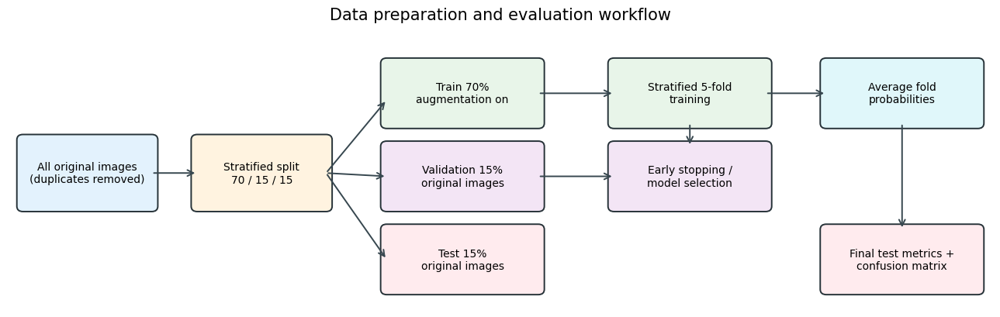

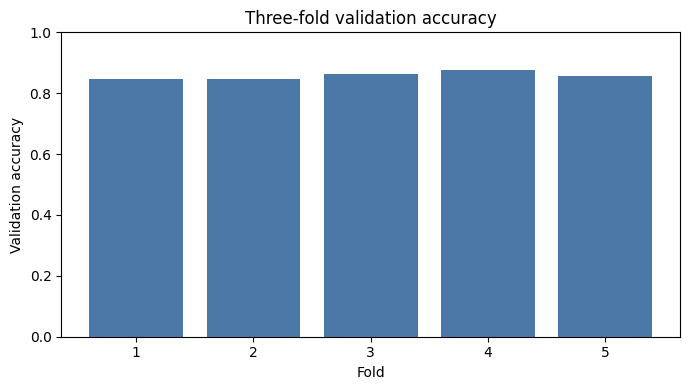

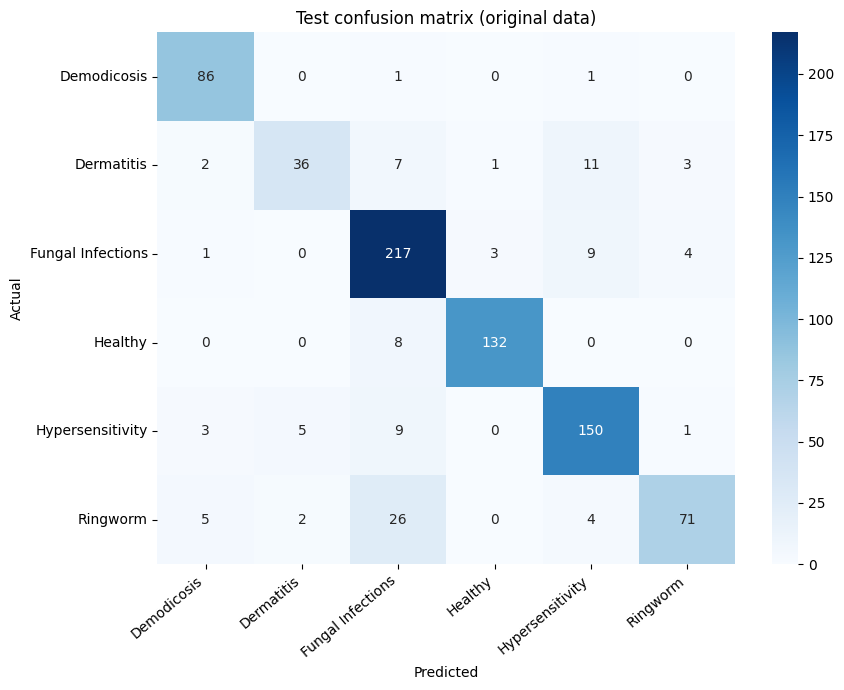

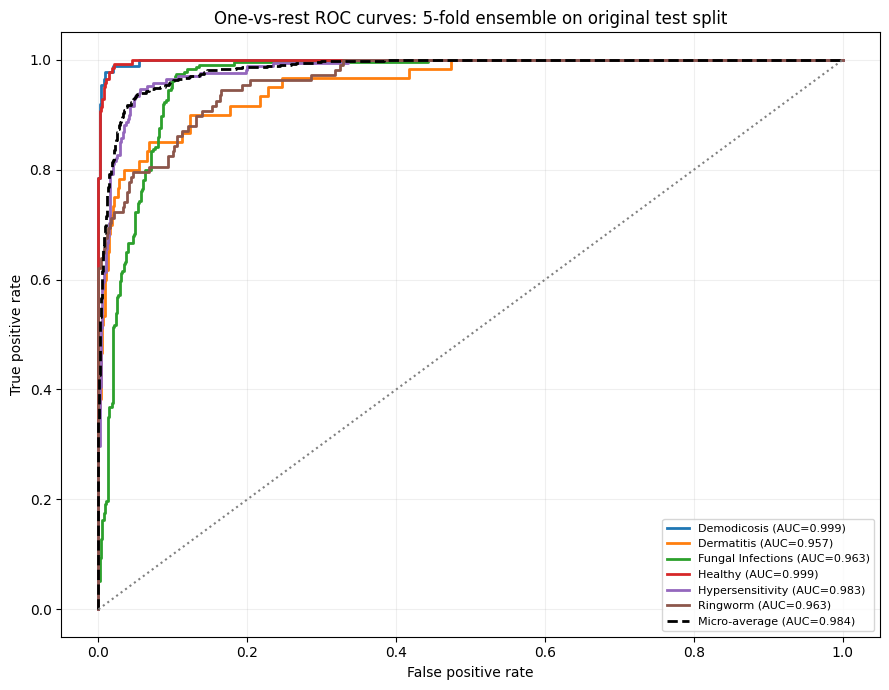

Matthews correlation coefficient (MCC): 0.8349
Macro precision: 0.8767
Macro recall: 0.8330
Macro F1: 0.8473
Test accuracy 95% bootstrap CI: [0.8409 0.8897]
Test MCC 95% bootstrap CI: [0.8041 0.8624]


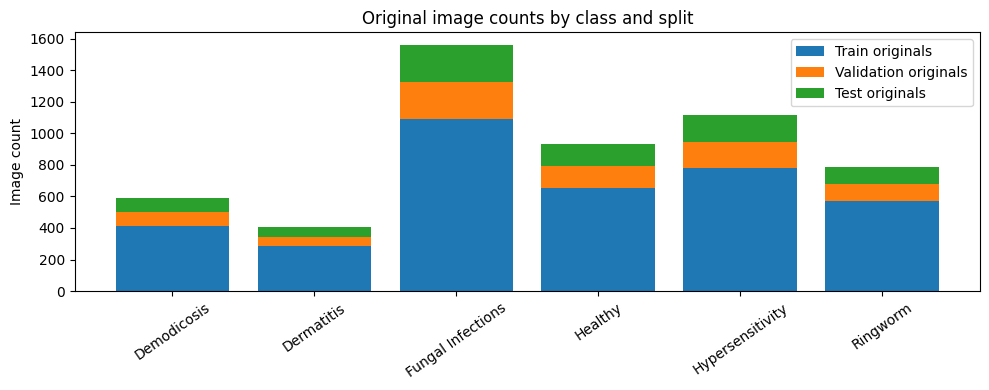

Per-class split counts (train, validation, test):
Demodicosis [412, 88, 88]
Dermatitis [284, 61, 60]
Fungal Infections [1093, 235, 234]
Healthy [652, 140, 140]
Hypersensitivity [780, 167, 168]
Ringworm [570, 107, 108]


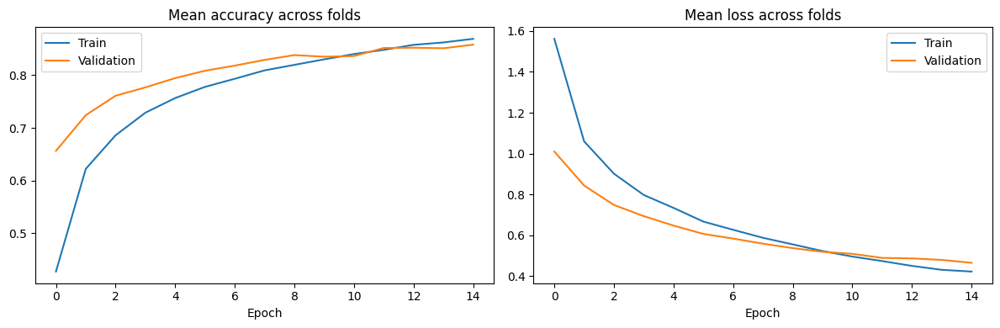

Grad-CAM image: /content/drive/MyDrive/Machine Learning Group 3/Dataset Final/Ringworm/436660568_816714827062296_2603836073731005890_n_jpg.rf.94d417b3859b6016d0514ca9a4976ed4.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step

Prediction: Ringworm (1.00)


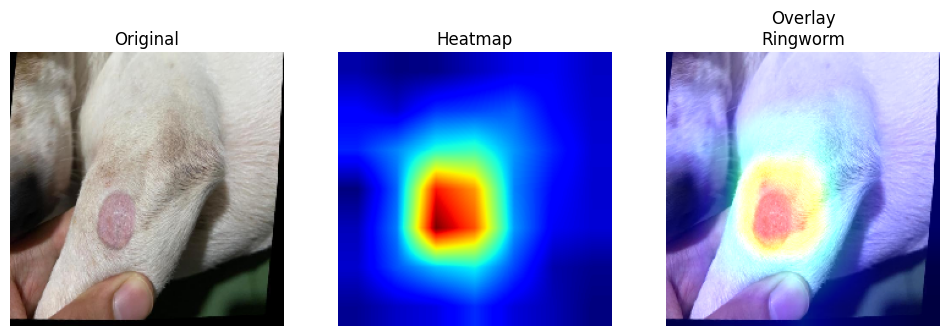

In [ ]:
# ============================================================
# STEP 1 : LOAD DATASET FROM GOOGLE DRIVE
# ============================================================
# Use the final dataset (already combined + segmentation results) from the following link (STEP 2 IN README):
# https://drive.google.com/drive/folders/1DkTKkC-1n2C0c5hb0Bm0hILIqvz6JbKl?usp=sharing
#
# How to use:
# 1. Open the link above
# 2. Click "Add shortcut to Drive"
# 3. Make sure the folder is saved in:
#    /content/drive/MyDrive/Machine Learning Group 3/Dataset Final
#
# EXTRA (Ringworm segmentation):
# 4. Open the shared folder "segmentation_v2" -> "Add shortcut to Drive"
#    so that this path exists:
#    /content/drive/MyDrive/segmentation_v2/roi_images/{train,val,test}
# ============================================================

# --- Connect to Google Drive ---
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# --- Import All Libraries ---
import tensorflow as tf
import numpy as np
import pathlib
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.applications import EfficientNetB0, ResNet50
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

# ============================================================
# DATASET SETUP: split original files first (70/15/15), then augment training only
# ============================================================
import pathlib, hashlib
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_curve, auc, matthews_corrcoef, f1_score, precision_score, recall_score
from tensorflow.keras.applications import EfficientNetB0, ResNet50
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

data_dir = pathlib.Path("/content/drive/MyDrive/Machine Learning Group 3/Dataset Final")
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123
N_SPLITS = 5
EPOCHS = 15
AUTOTUNE = tf.data.AUTOTUNE

# --- Ringworm segmentation (ROI) settings ---
# Ringworm ROI crops (U-Net VGG segmentation output, folder roi_images/train ONLY) are
# added to the TRAINING set. Validation and test contain original images only.
seg_dir = pathlib.Path("/content/drive/MyDrive/segmentation_v2/roi_images")  # adjust to your shortcut name
RINGWORM_NAME = "Ringworm"  # must match the class folder name in Dataset Final exactly

# Collect image files and remove exact byte duplicates before splitting.
valid_ext = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_names = sorted(p.name for p in data_dir.iterdir() if p.is_dir())
class_to_id = {name: i for i, name in enumerate(class_names)}

if not seg_dir.exists():
    raise FileNotFoundError(f"ROI folder not found: {seg_dir}")
if RINGWORM_NAME not in class_names:
    raise ValueError(f"Class '{RINGWORM_NAME}' not found in {class_names}")

def list_images(folder):
    return [p for p in sorted(folder.rglob('*')) if p.is_file() and p.suffix.lower() in valid_ext]

seen_hashes = set()
def unique_files(files):
    out = []
    for path in files:
        digest = hashlib.md5(path.read_bytes()).hexdigest()
        if digest not in seen_hashes:
            seen_hashes.add(digest)
            out.append(str(path))
    return out

# --- All classes: original images from Dataset Final, stratified 70/15/15 split ---
all_paths, all_labels = [], []
for name in class_names:
    files = unique_files(list_images(data_dir / name))
    all_paths += files
    all_labels += [class_to_id[name]] * len(files)
all_paths, all_labels = np.asarray(all_paths), np.asarray(all_labels, dtype=np.int32)

train_paths, hold_paths, y_train, y_hold = train_test_split(
    all_paths, all_labels, test_size=0.30, random_state=SEED, stratify=all_labels)
val_paths, test_paths, y_val, y_test = train_test_split(
    hold_paths, y_hold, test_size=0.50, random_state=SEED, stratify=y_hold)

# --- Ringworm segmentation: add ROI crops from roi_images/train to the TRAINING set only ---
rw_id = class_to_id[RINGWORM_NAME]
rw_roi_train = unique_files(list_images(seg_dir / "train"))
if len(rw_roi_train) == 0:
    raise ValueError(f"No images found in {seg_dir / 'train'}")
train_paths = np.concatenate([train_paths, np.asarray(rw_roi_train)])
y_train = np.concatenate([y_train, np.full(len(rw_roi_train), rw_id, dtype=np.int32)])
print(f"Added {len(rw_roi_train)} Ringworm ROI images (roi_images/train) to the training set only.")

paths = np.concatenate([train_paths, val_paths, test_paths])
labels = np.concatenate([y_train, y_val, y_test])

num_classes = len(class_names)
if num_classes < 2 or len(paths) == 0:
    raise ValueError(f"No usable class folders/images found in {data_dir}")
print(f"{len(paths)} unique images; {num_classes} classes: {class_names}")
print("Images per class:", {n: int((labels == i).sum()) for n, i in class_to_id.items()})
print(f"Split counts: train={len(train_paths)} ({len(train_paths)/len(paths):.1%}), "
      f"validation={len(val_paths)} ({len(val_paths)/len(paths):.1%}), "
      f"test={len(test_paths)} ({len(test_paths)/len(paths):.1%})")

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return tf.cast(image, tf.float32), label

def make_dataset(file_paths, file_labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((file_paths, file_labels))
    if training:
        ds = ds.shuffle(len(file_paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

val_ds = make_dataset(val_paths, y_val)
test_ds = make_dataset(test_paths, y_test)

# Moderate augmentation is applied inside the model, and is active only in training.
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal", seed=SEED),
    tf.keras.layers.RandomRotation(0.08, seed=SEED),
    tf.keras.layers.RandomZoom(0.10, seed=SEED),
    tf.keras.layers.RandomContrast(0.10, seed=SEED),
], name="train_only_augmentation")

def build_model():
    global effnet_base, resnet_base
    effnet_base = EfficientNetB0(weights='imagenet', include_top=False, input_shape=IMG_SIZE+(3,))
    resnet_base = ResNet50(weights='imagenet', include_top=False, input_shape=IMG_SIZE+(3,))
    effnet_base.trainable = False
    resnet_base.trainable = False
    inputs = tf.keras.Input(shape=IMG_SIZE+(3,), name='input_layer')
    augmented = data_augmentation(inputs)
    x1 = efficientnet_preprocess(augmented)
    x1 = effnet_base(x1, training=False)
    x1 = tf.keras.layers.GlobalAveragePooling2D(name='effnet_gap')(x1)
    x1 = tf.keras.layers.Dropout(0.25, name='effnet_dropout')(x1)
    x2 = resnet_preprocess(augmented)
    x2 = resnet_base(x2, training=False)
    x2 = tf.keras.layers.GlobalAveragePooling2D(name='resnet_gap')(x2)
    x2 = tf.keras.layers.Dropout(0.25, name='resnet_dropout')(x2)
    merged = tf.keras.layers.Concatenate()([x1, x2])
    x = tf.keras.layers.Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4), name='meta_dense_1')(merged)
    x = tf.keras.layers.Dropout(0.35, name='meta_dropout')(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax', name='output_layer')(x)
    model = tf.keras.Model(inputs, outputs, name='Stacking_EfficientNetB0_ResNet50')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# Three-fold stratified CV uses only the 70% training partition. The untouched
# original validation split controls early stopping; test is opened only at final evaluation.
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
fold_models, fold_histories, fold_scores = [], [], []
for fold, (fit_idx, fold_val_idx) in enumerate(skf.split(train_paths, y_train), start=1):
    print(f"\n=== Fold {fold}/{N_SPLITS} ===")
    fold_train_ds = make_dataset(train_paths[fit_idx], y_train[fit_idx], training=True)
    fold_val_ds = make_dataset(train_paths[fold_val_idx], y_train[fold_val_idx])
    model = build_model()
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-6),
    ]
    history = model.fit(fold_train_ds, validation_data=fold_val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=1)
    fold_histories.append(history.history)
    fold_models.append(model)
    score = model.evaluate(fold_val_ds, verbose=0)
    fold_scores.append(score[1])
    print(f"Fold {fold} internal validation accuracy: {score[1]:.4f}")

# Probability averaging across folds reduces variance without training a fourth model.
def ensemble_predict(ds):
    probs = [m.predict(ds, verbose=0) for m in fold_models]
    return np.mean(probs, axis=0)
stacked_model = fold_models[int(np.argmax(fold_scores))]  # used by the Grad-CAM section
# Keep Grad-CAM connected to the exact backbone weights of the selected fold.
effnet_base = stacked_model.get_layer('efficientnetb0')
resnet_base = stacked_model.get_layer('resnet50')
pred_val = np.argmax(ensemble_predict(val_ds), axis=1)
print(f"\nMean 5-fold internal validation accuracy: {np.mean(fold_scores):.4f} +/- {np.std(fold_scores):.4f}")
print(f"Ensemble validation accuracy: {accuracy_score(y_val, pred_val):.4f}")

# Final unbiased evaluation on the untouched 15% original test split.
y_true = y_test
y_prob = ensemble_predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)
print("\n=== Test classification report (5-fold ensemble) ===")
print(classification_report(y_true, y_pred, labels=np.arange(num_classes), target_names=class_names, zero_division=0))
print("Test accuracy:", accuracy_score(y_true, y_pred))
cm = confusion_matrix(y_true, y_pred, labels=np.arange(num_classes))

# Diagrams: split/training workflow, fold validation accuracy, and actual test confusion matrix.
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
fig, ax = plt.subplots(figsize=(13, 4.2)); ax.set_xlim(0, 13); ax.set_ylim(0, 4.2); ax.axis('off')
def box(x, y, w, h, label, color):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.08',facecolor=color,edgecolor='#263238',linewidth=1.4))
    ax.text(x+w/2,y+h/2,label,ha='center',va='center',fontsize=10,wrap=True)
def arrow(x1,y1,x2,y2): ax.add_patch(FancyArrowPatch((x1,y1),(x2,y2),arrowstyle='->',mutation_scale=14,color='#37474f',linewidth=1.4))
box(.2,1.55,1.7,1.0,'All original images\n(duplicates removed)','#e3f2fd')
box(2.5,1.55,1.7,1.0,'Stratified split\n70 / 15 / 15','#fff3e0')
box(5,2.8,2.0,.9,'Train 70%\naugmentation on','#e8f5e9')
box(5,1.55,2.0,.9,'Validation 15%\noriginal images','#f3e5f5')
box(5,.3,2.0,.9,'Test 15%\noriginal images','#ffebee')
box(8,2.8,2.0,.9,'Stratified 5-fold\ntraining','#e8f5e9')
box(10.8,2.8,2.0,.9,'Average fold\nprobabilities','#e0f7fa')
box(8,1.55,2.0,.9,'Early stopping /\nmodel selection','#f3e5f5')
box(10.8,.3,2.0,.9,'Final test metrics +\nconfusion matrix','#ffebee')
arrow(1.9,2.05,2.5,2.05); arrow(4.2,2.05,5,3.15); arrow(4.2,2.05,5,2.0); arrow(4.2,2.05,5,.75)
arrow(7,3.25,8,3.25); arrow(10,3.25,10.8,3.25); arrow(7,2.0,8,2.0); arrow(9,2.8,9,2.45); arrow(11.8,2.8,11.8,1.2)
ax.set_title('Data preparation and evaluation workflow',fontsize=15,pad=10); plt.tight_layout(); plt.show()

plt.figure(figsize=(7,4)); plt.bar(np.arange(1,N_SPLITS+1),fold_scores,color='#4c78a8')
plt.ylim(0,1); plt.xticks(np.arange(1,N_SPLITS+1)); plt.ylabel('Validation accuracy'); plt.xlabel('Fold')
plt.title('Three-fold validation accuracy'); plt.tight_layout(); plt.show()

plt.figure(figsize=(9,7)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Test confusion matrix (original data)'); plt.xticks(rotation=40,ha='right'); plt.yticks(rotation=0); plt.tight_layout(); plt.show()

# Multi-class one-vs-rest ROC curves on the untouched original test data.
from sklearn.preprocessing import label_binarize
y_test_bin = label_binarize(y_true, classes=np.arange(num_classes))
plt.figure(figsize=(9, 7))
for class_id, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_test_bin[:, class_id], y_prob[:, class_id])
    class_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{class_name} (AUC={class_auc:.3f})')
# Micro-average summarizes all class decisions.
fpr_micro, tpr_micro, _ = roc_curve(y_test_bin.ravel(), y_prob.ravel())
plt.plot(fpr_micro, tpr_micro, color='black', linestyle='--', lw=2,
         label=f'Micro-average (AUC={auc(fpr_micro, tpr_micro):.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle=':')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('One-vs-rest ROC curves: 5-fold ensemble on original test split')
plt.legend(loc='lower right', fontsize=8); plt.grid(alpha=.2); plt.tight_layout(); plt.show()

# Additional classification metrics. Bootstrap intervals are descriptive 95% CIs
# over test images and do not replace external validation.
mcc = matthews_corrcoef(y_true, y_pred)
print(f'Matthews correlation coefficient (MCC): {mcc:.4f}')
print(f"Macro precision: {precision_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro recall: {recall_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro F1: {f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
rng = np.random.default_rng(SEED)
boot_acc, boot_mcc = [], []
for _ in range(1000):
    idx = rng.integers(0, len(y_true), len(y_true))
    if len(np.unique(y_true[idx])) > 1:
        boot_acc.append(accuracy_score(y_true[idx], y_pred[idx]))
        boot_mcc.append(matthews_corrcoef(y_true[idx], y_pred[idx]))
print('Test accuracy 95% bootstrap CI:', np.percentile(boot_acc, [2.5, 97.5]).round(4))
print('Test MCC 95% bootstrap CI:', np.percentile(boot_mcc, [2.5, 97.5]).round(4))

# Show original-image counts by class for each untouched split.
distribution = np.column_stack([
    np.bincount(y_train, minlength=num_classes),
    np.bincount(y_val, minlength=num_classes),
    np.bincount(y_test, minlength=num_classes)])
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(class_names, distribution[:, 0], label='Train originals')
ax.bar(class_names, distribution[:, 1], bottom=distribution[:, 0], label='Validation originals')
ax.bar(class_names, distribution[:, 2], bottom=distribution[:, 0] + distribution[:, 1], label='Test originals')
ax.set_ylabel('Image count'); ax.set_title('Original image counts by class and split')
ax.tick_params(axis='x', rotation=35); ax.legend(); plt.tight_layout(); plt.show()
print('Per-class split counts (train, validation, test):')
for i, name in enumerate(class_names): print(name, distribution[i].tolist())

# Average fold learning curves for training/validation diagrams.
common_epochs = min(len(h['accuracy']) for h in fold_histories)
mean_train_acc = np.mean([h['accuracy'][:common_epochs] for h in fold_histories], axis=0)
mean_val_acc = np.mean([h['val_accuracy'][:common_epochs] for h in fold_histories], axis=0)
mean_train_loss = np.mean([h['loss'][:common_epochs] for h in fold_histories], axis=0)
mean_val_loss = np.mean([h['val_loss'][:common_epochs] for h in fold_histories], axis=0)
plt.figure(figsize=(12,4))
plt.subplot(1,2,1); plt.plot(mean_train_acc,label='Train'); plt.plot(mean_val_acc,label='Validation'); plt.title('Mean accuracy across folds'); plt.xlabel('Epoch'); plt.legend()
plt.subplot(1,2,2); plt.plot(mean_train_loss,label='Train'); plt.plot(mean_val_loss,label='Validation'); plt.title('Mean loss across folds'); plt.xlabel('Epoch'); plt.legend()
plt.tight_layout(); plt.show()

# ----------------------------- Grad-CAM Manual Input -----------------------------

import cv2

# Convert tensor to uint8 (for visualization)
def tensor_to_uint8(img_tensor):
    img = img_tensor.numpy()
    if img.max() <= 1.0:
        img = (img * 255).astype('uint8')
    return img.astype('uint8')

# Grad-CAM function for ensemble model
def gradcam_for_ensemble(stack_model, effnet_base, resnet_base, img, class_index=None):

    img_tensor = tf.expand_dims(img, axis=0)

    # Preprocessing based on each model
    x_eff = efficientnet_preprocess(tf.cast(img_tensor, tf.float32))
    x_res = resnet_preprocess(tf.cast(img_tensor, tf.float32))

    # Retrieve layers based on training architecture
    effnet_gap = stack_model.get_layer('effnet_gap')
    effnet_dropout = stack_model.get_layer('effnet_dropout')
    resnet_gap = stack_model.get_layer('resnet_gap')
    resnet_dropout = stack_model.get_layer('resnet_dropout')
    meta_dense = stack_model.get_layer('meta_dense_1')
    meta_dropout = stack_model.get_layer('meta_dropout')
    output_layer = stack_model.get_layer('output_layer')

    with tf.GradientTape(persistent=True) as tape:
        # Forward pass
        act1 = effnet_base(x_eff, training=False)
        act2 = resnet_base(x_res, training=False)

        tape.watch(act1)
        tape.watch(act2)

        # Must match training pipeline exactly
        gap1 = effnet_gap(act1)
        gap1 = effnet_dropout(gap1, training=False)

        gap2 = resnet_gap(act2)
        gap2 = resnet_dropout(gap2, training=False)

        concat = tf.concat([gap1, gap2], axis=-1)

        x = meta_dense(concat)
        x = meta_dropout(x, training=False)
        preds = output_layer(x)

        # Use predicted class if not specified
        if class_index is None:
            class_index = tf.argmax(preds[0])

        class_score = preds[:, class_index]

    # Compute gradients
    grads1 = tape.gradient(class_score, act1)
    grads2 = tape.gradient(class_score, act2)

    # Compute weights
    weights1 = tf.reduce_mean(grads1, axis=(1,2))
    weights2 = tf.reduce_mean(grads2, axis=(1,2))

    # Compute CAM
    cam1 = tf.reduce_sum(tf.multiply(act1, weights1[:, None, None, :]), axis=-1)[0].numpy()
    cam2 = tf.reduce_sum(tf.multiply(act2, weights2[:, None, None, :]), axis=-1)[0].numpy()

    # Normalize heatmap
    heatmap = (cam1 + cam2) / 2
    heatmap = np.maximum(heatmap, 0)
    heatmap = heatmap / (heatmap.max() + 1e-8)
    heatmap = cv2.resize(heatmap, (IMG_SIZE[1], IMG_SIZE[0]))

    return heatmap, preds.numpy()[0], int(class_index.numpy() if hasattr(class_index, 'numpy') else class_index)

# Overlay heatmap onto image
def overlay_heatmap_on_image(img, heatmap):
    heatmap = np.uint8(255 * heatmap)
    heatmap_color = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(img, 1, heatmap_color, 0.5, 0)
    return heatmap_color, overlay

# ----------------------------- USER IMAGE INPUT -----------------------------
# Default: first Ringworm image (original, not ROI) from the untouched test split.
# To use a specific file, replace with: img_path = "/content/drive/MyDrive/.../your_image.jpg"
img_path = test_paths[y_test == class_to_id[RINGWORM_NAME]][0]
print("Grad-CAM image:", img_path)

img = tf.keras.preprocessing.image.load_img(img_path, target_size=IMG_SIZE)
img_array = tf.keras.preprocessing.image.img_to_array(img)
img_uint8 = img_array.astype("uint8")

# Prediction
pred = stacked_model.predict(tf.expand_dims(img_array, axis=0))
pred_class = np.argmax(pred)
pred_conf = pred[0][pred_class]

print(f"\nPrediction: {class_names[pred_class]} ({pred_conf:.2f})")

# Grad-CAM
heatmap, _, _ = gradcam_for_ensemble(stacked_model, effnet_base, resnet_base, img_array)

heatmap_rgb, overlay = overlay_heatmap_on_image(img_uint8, heatmap)

# Visualization
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(img_uint8)
plt.title("Original")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(heatmap, cmap='jet')
plt.title("Heatmap")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(overlay)
plt.title(f"Overlay\n{class_names[pred_class]}")
plt.axis('off')

plt.show()

Mounted at /content/drive
Added 68 Ringworm ROI images (roi_images/train) to the training set only.
5387 unique images; 6 classes: ['Demodicosis', 'Dermatitis', 'Fungal Infections', 'Healthy', 'Hypersensitivity', 'Ringworm']
Images per class: {'Demodicosis': 588, 'Dermatitis': 405, 'Fungal Infections': 1562, 'Healthy': 932, 'Hypersensitivity': 1115, 'Ringworm': 785}
Split counts: train=3791 (70.4%), validation=798 (14.8%), test=798 (14.8%)

=== Fold 1/5 ===
Epoch 1/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 49s 348ms/step - accuracy: 0.4189 - loss: 1.5983 - val_accuracy: 0.6601 - val_loss: 1.0338 - learning_rate: 1.0000e-04
Epoch 2/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 26s 277ms/step - accuracy: 0.6217 - loss: 1.0836 - val_accuracy: 0.7233 - val_loss: 0.8650 - learning_rate: 1.0000e-04
Epoch 3/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 26s 277ms/step - accuracy: 0.6896 - loss: 0.9064 - val_accuracy: 0.7602 - val_loss: 0.7764 - learning_rate: 1.0000e-04
Epoch 4/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 26s 278ms/step - accuracy: 0.

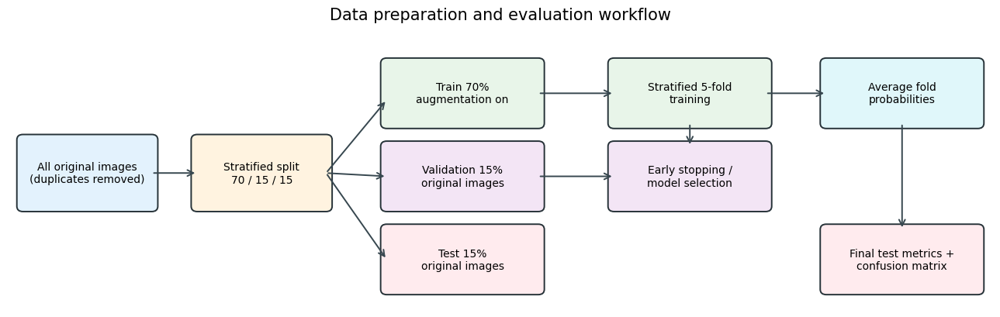

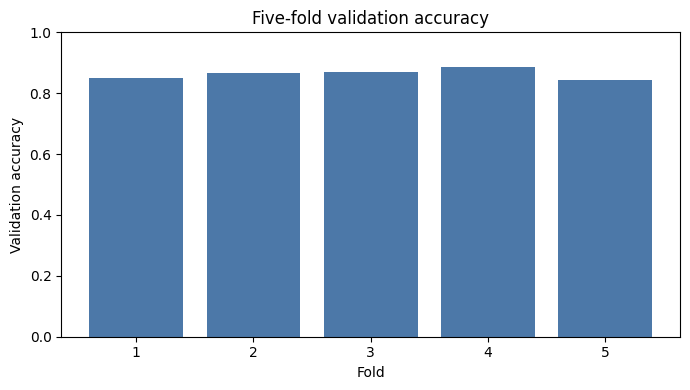

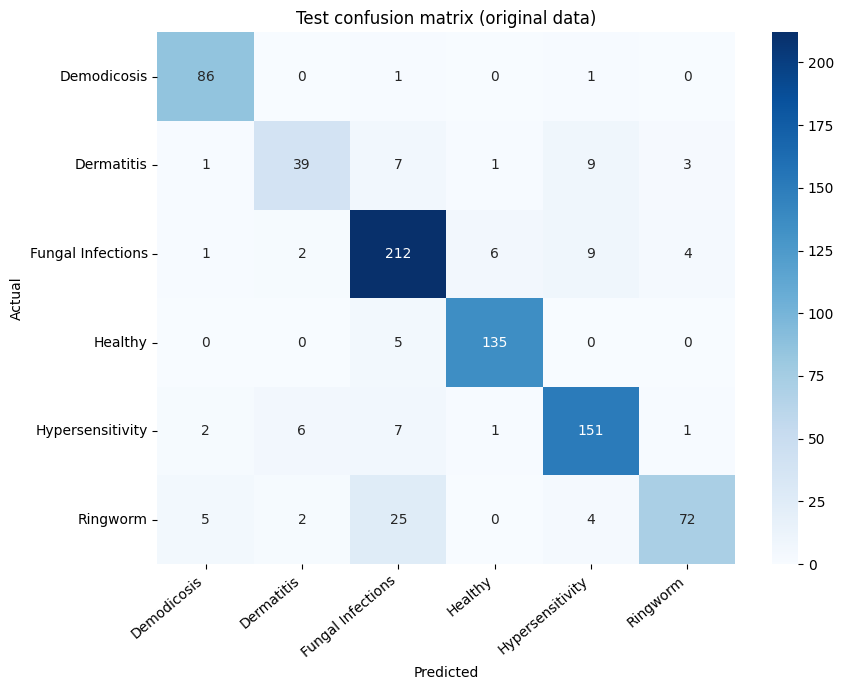

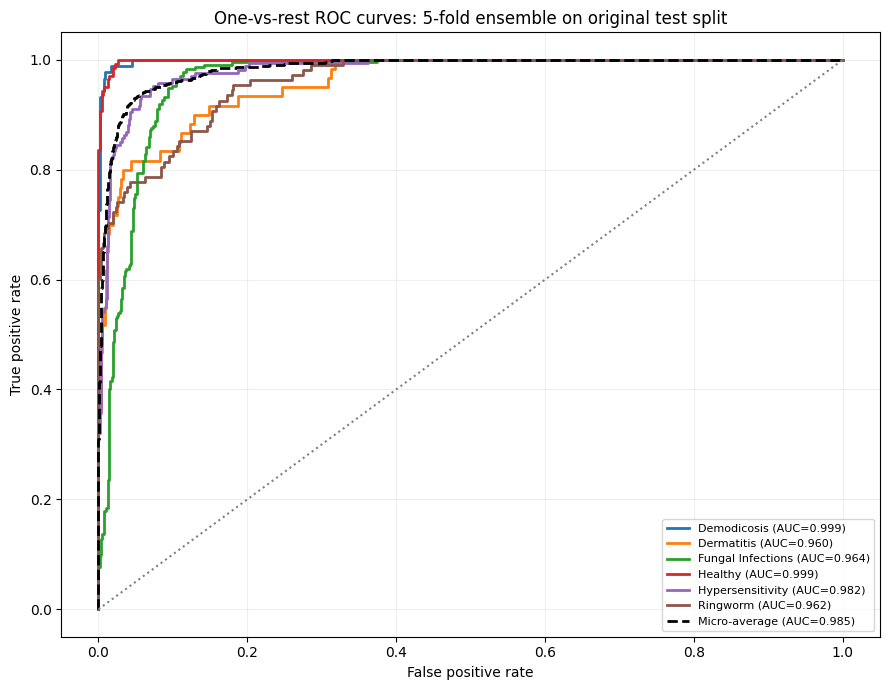

Matthews correlation coefficient (MCC): 0.8393
Macro precision: 0.8730
Macro recall: 0.8438
Macro F1: 0.8537
Test accuracy 95% bootstrap CI: [0.8459 0.8935]
Test MCC 95% bootstrap CI: [0.8084 0.867 ]


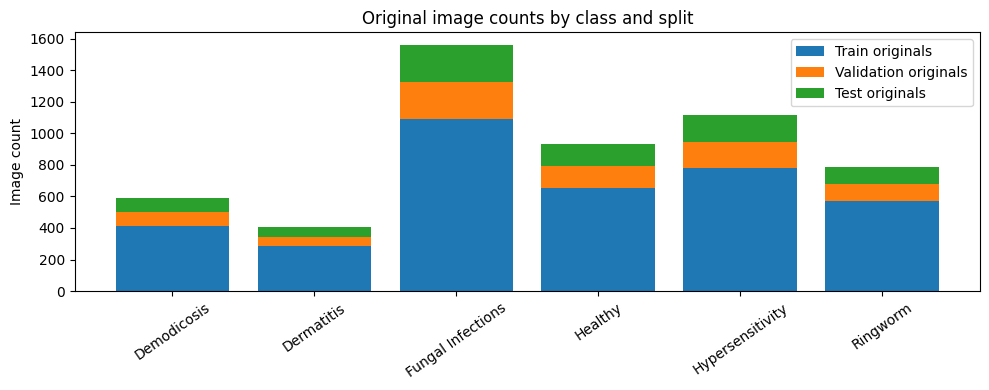

Per-class split counts (train, validation, test):
Demodicosis [412, 88, 88]
Dermatitis [284, 61, 60]
Fungal Infections [1093, 235, 234]
Healthy [652, 140, 140]
Hypersensitivity [780, 167, 168]
Ringworm [570, 107, 108]


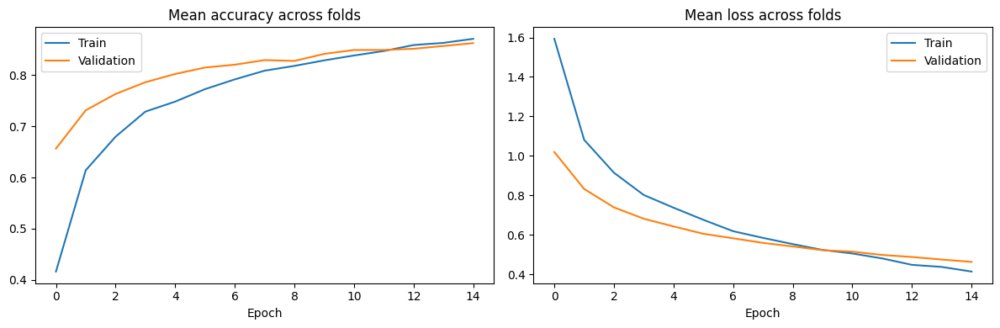

Grad-CAM image: /content/drive/MyDrive/Machine Learning Group 3/Dataset Final/Ringworm/436660568_816714827062296_2603836073731005890_n_jpg.rf.94d417b3859b6016d0514ca9a4976ed4.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step

Prediction: Ringworm (1.00)


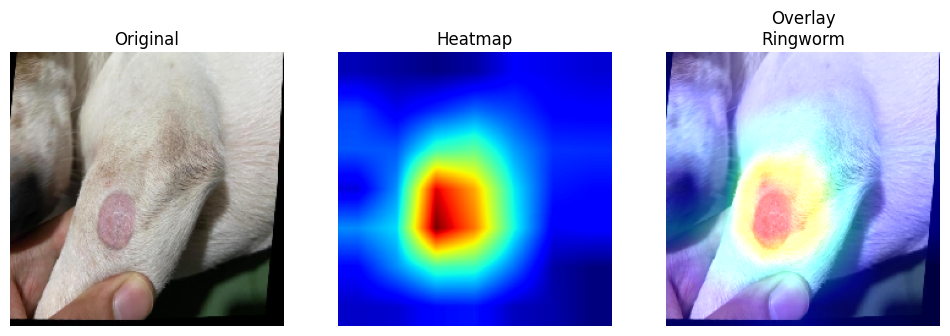

In [ ]:
# ============================================================
# STEP 1 : LOAD DATASET FROM GOOGLE DRIVE
# ============================================================
# Use the final dataset (already combined + segmentation results) from the following link (STEP 2 IN README):
# https://drive.google.com/drive/folders/1DkTKkC-1n2C0c5hb0Bm0hILIqvz6JbKl?usp=sharing
#
# How to use:
# 1. Open the link above
# 2. Click "Add shortcut to Drive"
# 3. Make sure the folder is saved in:
#    /content/drive/MyDrive/Machine Learning Group 3/Dataset Final
#
# EXTRA (Ringworm segmentation):
# 4. Open the shared folder "segmentation_v2" -> "Add shortcut to Drive"
#    so that this path exists:
#    /content/drive/MyDrive/segmentation_v2/roi_images/{train,val,test}
# ============================================================

# --- Connect to Google Drive ---
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# --- Import All Libraries ---
import tensorflow as tf
import numpy as np
import pathlib
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.applications import EfficientNetB0, ResNet50
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

# ============================================================
# DATASET SETUP: split original files first (70/15/15), then augment training only
# ============================================================
import pathlib, hashlib
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_curve, auc, matthews_corrcoef, f1_score, precision_score, recall_score
from tensorflow.keras.applications import EfficientNetB0, ResNet50
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

data_dir = pathlib.Path("/content/drive/MyDrive/Machine Learning Group 3/Dataset Final")
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123
N_SPLITS = 5
EPOCHS = 15
AUTOTUNE = tf.data.AUTOTUNE
tf.keras.utils.set_random_seed(SEED)  # fix Python/NumPy/TensorFlow seeds so runs are comparable

# Set to False to run the baseline WITHOUT segmentation ROI (for a fair with/without comparison).
USE_ROI = True

# --- Ringworm segmentation (ROI) settings ---
# Ringworm ROI crops (U-Net VGG segmentation output, folder roi_images/train ONLY) are
# added to the TRAINING set. Validation and test contain original images only.
seg_dir = pathlib.Path("/content/drive/MyDrive/segmentation_v2/roi_images")  # adjust to your shortcut name
RINGWORM_NAME = "Ringworm"  # must match the class folder name in Dataset Final exactly

# Collect image files and remove exact byte duplicates before splitting.
valid_ext = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_names = sorted(p.name for p in data_dir.iterdir() if p.is_dir())
class_to_id = {name: i for i, name in enumerate(class_names)}

if USE_ROI and not seg_dir.exists():
    raise FileNotFoundError(f"ROI folder not found: {seg_dir}")
if RINGWORM_NAME not in class_names:
    raise ValueError(f"Class '{RINGWORM_NAME}' not found in {class_names}")

def list_images(folder):
    return [p for p in sorted(folder.rglob('*')) if p.is_file() and p.suffix.lower() in valid_ext]

seen_hashes = set()
def unique_files(files):
    out = []
    for path in files:
        digest = hashlib.md5(path.read_bytes()).hexdigest()
        if digest not in seen_hashes:
            seen_hashes.add(digest)
            out.append(str(path))
    return out

# --- All classes: original images from Dataset Final, stratified 70/15/15 split ---
all_paths, all_labels = [], []
for name in class_names:
    files = unique_files(list_images(data_dir / name))
    all_paths += files
    all_labels += [class_to_id[name]] * len(files)
all_paths, all_labels = np.asarray(all_paths), np.asarray(all_labels, dtype=np.int32)

train_paths, hold_paths, y_train, y_hold = train_test_split(
    all_paths, all_labels, test_size=0.30, random_state=SEED, stratify=all_labels)
val_paths, test_paths, y_val, y_test = train_test_split(
    hold_paths, y_hold, test_size=0.50, random_state=SEED, stratify=y_hold)

# --- Ringworm segmentation: add ROI crops from roi_images/train to the TRAINING set only ---
rw_id = class_to_id[RINGWORM_NAME]
if USE_ROI:
    rw_roi_train = unique_files(list_images(seg_dir / "train"))
    if len(rw_roi_train) == 0:
        raise ValueError(f"No images found in {seg_dir / 'train'}")
    train_paths = np.concatenate([train_paths, np.asarray(rw_roi_train)])
    y_train = np.concatenate([y_train, np.full(len(rw_roi_train), rw_id, dtype=np.int32)])
    print(f"Added {len(rw_roi_train)} Ringworm ROI images (roi_images/train) to the training set only.")
else:
    print("USE_ROI=False: baseline run without segmentation ROI.")

paths = np.concatenate([train_paths, val_paths, test_paths])
labels = np.concatenate([y_train, y_val, y_test])

num_classes = len(class_names)
if num_classes < 2 or len(paths) == 0:
    raise ValueError(f"No usable class folders/images found in {data_dir}")
print(f"{len(paths)} unique images; {num_classes} classes: {class_names}")
print("Images per class:", {n: int((labels == i).sum()) for n, i in class_to_id.items()})
print(f"Split counts: train={len(train_paths)} ({len(train_paths)/len(paths):.1%}), "
      f"validation={len(val_paths)} ({len(val_paths)/len(paths):.1%}), "
      f"test={len(test_paths)} ({len(test_paths)/len(paths):.1%})")

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return tf.cast(image, tf.float32), label

def make_dataset(file_paths, file_labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((file_paths, file_labels))
    if training:
        ds = ds.shuffle(len(file_paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

val_ds = make_dataset(val_paths, y_val)
test_ds = make_dataset(test_paths, y_test)

# Moderate augmentation is applied inside the model, and is active only in training.
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal", seed=SEED),
    tf.keras.layers.RandomRotation(0.08, seed=SEED),
    tf.keras.layers.RandomZoom(0.10, seed=SEED),
    tf.keras.layers.RandomContrast(0.10, seed=SEED),
], name="train_only_augmentation")

def build_model():
    global effnet_base, resnet_base
    effnet_base = EfficientNetB0(weights='imagenet', include_top=False, input_shape=IMG_SIZE+(3,))
    resnet_base = ResNet50(weights='imagenet', include_top=False, input_shape=IMG_SIZE+(3,))
    effnet_base.trainable = False
    resnet_base.trainable = False
    inputs = tf.keras.Input(shape=IMG_SIZE+(3,), name='input_layer')
    augmented = data_augmentation(inputs)
    x1 = efficientnet_preprocess(augmented)
    x1 = effnet_base(x1, training=False)
    x1 = tf.keras.layers.GlobalAveragePooling2D(name='effnet_gap')(x1)
    x1 = tf.keras.layers.Dropout(0.25, name='effnet_dropout')(x1)
    x2 = resnet_preprocess(augmented)
    x2 = resnet_base(x2, training=False)
    x2 = tf.keras.layers.GlobalAveragePooling2D(name='resnet_gap')(x2)
    x2 = tf.keras.layers.Dropout(0.25, name='resnet_dropout')(x2)
    merged = tf.keras.layers.Concatenate()([x1, x2])
    x = tf.keras.layers.Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4), name='meta_dense_1')(merged)
    x = tf.keras.layers.Dropout(0.35, name='meta_dropout')(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax', name='output_layer')(x)
    model = tf.keras.Model(inputs, outputs, name='Stacking_EfficientNetB0_ResNet50')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# Five-fold stratified CV uses only the 70% training partition. The untouched
# original validation split controls early stopping; test is opened only at final evaluation.
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
fold_models, fold_histories, fold_scores = [], [], []
for fold, (fit_idx, fold_val_idx) in enumerate(skf.split(train_paths, y_train), start=1):
    print(f"\n=== Fold {fold}/{N_SPLITS} ===")
    fold_train_ds = make_dataset(train_paths[fit_idx], y_train[fit_idx], training=True)
    fold_val_ds = make_dataset(train_paths[fold_val_idx], y_train[fold_val_idx])
    model = build_model()
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-6),
    ]
    history = model.fit(fold_train_ds, validation_data=fold_val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=1)
    fold_histories.append(history.history)
    fold_models.append(model)
    score = model.evaluate(fold_val_ds, verbose=0)
    fold_scores.append(score[1])
    print(f"Fold {fold} internal validation accuracy: {score[1]:.4f}")

# Probability averaging across folds reduces variance without training an additional model.
def ensemble_predict(ds):
    probs = [m.predict(ds, verbose=0) for m in fold_models]
    return np.mean(probs, axis=0)
stacked_model = fold_models[int(np.argmax(fold_scores))]  # used by the Grad-CAM section
# Keep Grad-CAM connected to the exact backbone weights of the selected fold.
effnet_base = stacked_model.get_layer('efficientnetb0')
resnet_base = stacked_model.get_layer('resnet50')
pred_val = np.argmax(ensemble_predict(val_ds), axis=1)
print(f"\nMean 5-fold internal validation accuracy: {np.mean(fold_scores):.4f} +/- {np.std(fold_scores):.4f}")
print(f"Ensemble validation accuracy: {accuracy_score(y_val, pred_val):.4f}")

# Final unbiased evaluation on the untouched 15% original test split.
y_true = y_test
y_prob = ensemble_predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)
print("\n=== Test classification report (5-fold ensemble) ===")
print(classification_report(y_true, y_pred, labels=np.arange(num_classes), target_names=class_names, zero_division=0))
print("Test accuracy:", accuracy_score(y_true, y_pred))
cm = confusion_matrix(y_true, y_pred, labels=np.arange(num_classes))

# Diagrams: split/training workflow, fold validation accuracy, and actual test confusion matrix.
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
fig, ax = plt.subplots(figsize=(13, 4.2)); ax.set_xlim(0, 13); ax.set_ylim(0, 4.2); ax.axis('off')
def box(x, y, w, h, label, color):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.08',facecolor=color,edgecolor='#263238',linewidth=1.4))
    ax.text(x+w/2,y+h/2,label,ha='center',va='center',fontsize=10,wrap=True)
def arrow(x1,y1,x2,y2): ax.add_patch(FancyArrowPatch((x1,y1),(x2,y2),arrowstyle='->',mutation_scale=14,color='#37474f',linewidth=1.4))
box(.2,1.55,1.7,1.0,'All original images\n(duplicates removed)','#e3f2fd')
box(2.5,1.55,1.7,1.0,'Stratified split\n70 / 15 / 15','#fff3e0')
box(5,2.8,2.0,.9,'Train 70%\naugmentation on','#e8f5e9')
box(5,1.55,2.0,.9,'Validation 15%\noriginal images','#f3e5f5')
box(5,.3,2.0,.9,'Test 15%\noriginal images','#ffebee')
box(8,2.8,2.0,.9,'Stratified 5-fold\ntraining','#e8f5e9')
box(10.8,2.8,2.0,.9,'Average fold\nprobabilities','#e0f7fa')
box(8,1.55,2.0,.9,'Early stopping /\nmodel selection','#f3e5f5')
box(10.8,.3,2.0,.9,'Final test metrics +\nconfusion matrix','#ffebee')
arrow(1.9,2.05,2.5,2.05); arrow(4.2,2.05,5,3.15); arrow(4.2,2.05,5,2.0); arrow(4.2,2.05,5,.75)
arrow(7,3.25,8,3.25); arrow(10,3.25,10.8,3.25); arrow(7,2.0,8,2.0); arrow(9,2.8,9,2.45); arrow(11.8,2.8,11.8,1.2)
ax.set_title('Data preparation and evaluation workflow',fontsize=15,pad=10); plt.tight_layout(); plt.show()

plt.figure(figsize=(7,4)); plt.bar(np.arange(1,N_SPLITS+1),fold_scores,color='#4c78a8')
plt.ylim(0,1); plt.xticks(np.arange(1,N_SPLITS+1)); plt.ylabel('Validation accuracy'); plt.xlabel('Fold')
plt.title('Five-fold validation accuracy'); plt.tight_layout(); plt.show()

plt.figure(figsize=(9,7)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Test confusion matrix (original data)'); plt.xticks(rotation=40,ha='right'); plt.yticks(rotation=0); plt.tight_layout(); plt.show()

# Multi-class one-vs-rest ROC curves on the untouched original test data.
from sklearn.preprocessing import label_binarize
y_test_bin = label_binarize(y_true, classes=np.arange(num_classes))
plt.figure(figsize=(9, 7))
for class_id, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_test_bin[:, class_id], y_prob[:, class_id])
    class_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{class_name} (AUC={class_auc:.3f})')
# Micro-average summarizes all class decisions.
fpr_micro, tpr_micro, _ = roc_curve(y_test_bin.ravel(), y_prob.ravel())
plt.plot(fpr_micro, tpr_micro, color='black', linestyle='--', lw=2,
         label=f'Micro-average (AUC={auc(fpr_micro, tpr_micro):.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle=':')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('One-vs-rest ROC curves: 5-fold ensemble on original test split')
plt.legend(loc='lower right', fontsize=8); plt.grid(alpha=.2); plt.tight_layout(); plt.show()

# Additional classification metrics. Bootstrap intervals are descriptive 95% CIs
# over test images and do not replace external validation.
mcc = matthews_corrcoef(y_true, y_pred)
print(f'Matthews correlation coefficient (MCC): {mcc:.4f}')
print(f"Macro precision: {precision_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro recall: {recall_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro F1: {f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
rng = np.random.default_rng(SEED)
boot_acc, boot_mcc = [], []
for _ in range(1000):
    idx = rng.integers(0, len(y_true), len(y_true))
    if len(np.unique(y_true[idx])) > 1:
        boot_acc.append(accuracy_score(y_true[idx], y_pred[idx]))
        boot_mcc.append(matthews_corrcoef(y_true[idx], y_pred[idx]))
print('Test accuracy 95% bootstrap CI:', np.percentile(boot_acc, [2.5, 97.5]).round(4))
print('Test MCC 95% bootstrap CI:', np.percentile(boot_mcc, [2.5, 97.5]).round(4))

# Show original-image counts by class for each untouched split.
distribution = np.column_stack([
    np.bincount(y_train, minlength=num_classes),
    np.bincount(y_val, minlength=num_classes),
    np.bincount(y_test, minlength=num_classes)])
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(class_names, distribution[:, 0], label='Train originals')
ax.bar(class_names, distribution[:, 1], bottom=distribution[:, 0], label='Validation originals')
ax.bar(class_names, distribution[:, 2], bottom=distribution[:, 0] + distribution[:, 1], label='Test originals')
ax.set_ylabel('Image count'); ax.set_title('Original image counts by class and split')
ax.tick_params(axis='x', rotation=35); ax.legend(); plt.tight_layout(); plt.show()
print('Per-class split counts (train, validation, test):')
for i, name in enumerate(class_names): print(name, distribution[i].tolist())

# Average fold learning curves for training/validation diagrams.
common_epochs = min(len(h['accuracy']) for h in fold_histories)
mean_train_acc = np.mean([h['accuracy'][:common_epochs] for h in fold_histories], axis=0)
mean_val_acc = np.mean([h['val_accuracy'][:common_epochs] for h in fold_histories], axis=0)
mean_train_loss = np.mean([h['loss'][:common_epochs] for h in fold_histories], axis=0)
mean_val_loss = np.mean([h['val_loss'][:common_epochs] for h in fold_histories], axis=0)
plt.figure(figsize=(12,4))
plt.subplot(1,2,1); plt.plot(mean_train_acc,label='Train'); plt.plot(mean_val_acc,label='Validation'); plt.title('Mean accuracy across folds'); plt.xlabel('Epoch'); plt.legend()
plt.subplot(1,2,2); plt.plot(mean_train_loss,label='Train'); plt.plot(mean_val_loss,label='Validation'); plt.title('Mean loss across folds'); plt.xlabel('Epoch'); plt.legend()
plt.tight_layout(); plt.show()

# ----------------------------- Grad-CAM Manual Input -----------------------------

import cv2

# Convert tensor to uint8 (for visualization)
def tensor_to_uint8(img_tensor):
    img = img_tensor.numpy()
    if img.max() <= 1.0:
        img = (img * 255).astype('uint8')
    return img.astype('uint8')

# Grad-CAM function for ensemble model
def gradcam_for_ensemble(stack_model, effnet_base, resnet_base, img, class_index=None):

    img_tensor = tf.expand_dims(img, axis=0)

    # Preprocessing based on each model
    x_eff = efficientnet_preprocess(tf.cast(img_tensor, tf.float32))
    x_res = resnet_preprocess(tf.cast(img_tensor, tf.float32))

    # Retrieve layers based on training architecture
    effnet_gap = stack_model.get_layer('effnet_gap')
    effnet_dropout = stack_model.get_layer('effnet_dropout')
    resnet_gap = stack_model.get_layer('resnet_gap')
    resnet_dropout = stack_model.get_layer('resnet_dropout')
    meta_dense = stack_model.get_layer('meta_dense_1')
    meta_dropout = stack_model.get_layer('meta_dropout')
    output_layer = stack_model.get_layer('output_layer')

    with tf.GradientTape(persistent=True) as tape:
        # Forward pass
        act1 = effnet_base(x_eff, training=False)
        act2 = resnet_base(x_res, training=False)

        tape.watch(act1)
        tape.watch(act2)

        # Must match training pipeline exactly
        gap1 = effnet_gap(act1)
        gap1 = effnet_dropout(gap1, training=False)

        gap2 = resnet_gap(act2)
        gap2 = resnet_dropout(gap2, training=False)

        concat = tf.concat([gap1, gap2], axis=-1)

        x = meta_dense(concat)
        x = meta_dropout(x, training=False)
        preds = output_layer(x)

        # Use predicted class if not specified
        if class_index is None:
            class_index = tf.argmax(preds[0])

        class_score = preds[:, class_index]

    # Compute gradients
    grads1 = tape.gradient(class_score, act1)
    grads2 = tape.gradient(class_score, act2)

    # Compute weights
    weights1 = tf.reduce_mean(grads1, axis=(1,2))
    weights2 = tf.reduce_mean(grads2, axis=(1,2))

    # Compute CAM
    cam1 = tf.reduce_sum(tf.multiply(act1, weights1[:, None, None, :]), axis=-1)[0].numpy()
    cam2 = tf.reduce_sum(tf.multiply(act2, weights2[:, None, None, :]), axis=-1)[0].numpy()

    # Normalize heatmap
    heatmap = (cam1 + cam2) / 2
    heatmap = np.maximum(heatmap, 0)
    heatmap = heatmap / (heatmap.max() + 1e-8)
    heatmap = cv2.resize(heatmap, (IMG_SIZE[1], IMG_SIZE[0]))

    return heatmap, preds.numpy()[0], int(class_index.numpy() if hasattr(class_index, 'numpy') else class_index)

# Overlay heatmap onto image
def overlay_heatmap_on_image(img, heatmap):
    heatmap = np.uint8(255 * heatmap)
    heatmap_color = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(img, 1, heatmap_color, 0.5, 0)
    return heatmap_color, overlay

# ----------------------------- USER IMAGE INPUT -----------------------------
# Default: first Ringworm image (original, not ROI) from the untouched test split.
# To use a specific file, replace with: img_path = "/content/drive/MyDrive/.../your_image.jpg"
img_path = test_paths[y_test == class_to_id[RINGWORM_NAME]][0]
print("Grad-CAM image:", img_path)

img = tf.keras.preprocessing.image.load_img(img_path, target_size=IMG_SIZE)
img_array = tf.keras.preprocessing.image.img_to_array(img)
img_uint8 = img_array.astype("uint8")

# Prediction
pred = stacked_model.predict(tf.expand_dims(img_array, axis=0))
pred_class = np.argmax(pred)
pred_conf = pred[0][pred_class]

print(f"\nPrediction: {class_names[pred_class]} ({pred_conf:.2f})")

# Grad-CAM
heatmap, _, _ = gradcam_for_ensemble(stacked_model, effnet_base, resnet_base, img_array)

heatmap_rgb, overlay = overlay_heatmap_on_image(img_uint8, heatmap)

# Visualization
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(img_uint8)
plt.title("Original")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(heatmap, cmap='jet')
plt.title("Heatmap")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(overlay)
plt.title(f"Overlay\n{class_names[pred_class]}")
plt.axis('off')

plt.show()

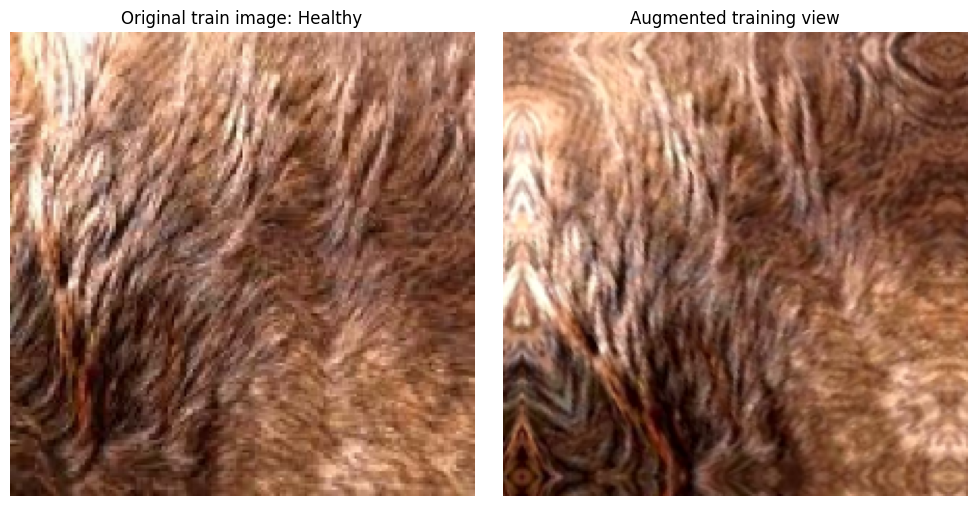

In [ ]:
# Visual check: augmentation is demonstrated from the training split only.
import matplotlib.pyplot as plt

sample_path = train_paths[0]
sample_label = class_names[int(y_train[0])]
original, _ = load_image(sample_path, y_train[0])
augmented = data_augmentation(tf.expand_dims(original, 0), training=True)[0]
original = tf.cast(tf.clip_by_value(original, 0, 255), tf.uint8).numpy()
augmented = tf.cast(tf.clip_by_value(augmented, 0, 255), tf.uint8).numpy()

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1); plt.imshow(original); plt.title(f"Original train image: {sample_label}"); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(augmented); plt.title("Augmented training view"); plt.axis('off')
plt.tight_layout(); plt.show()


Mounted at /content/drive
Added 68 Ringworm ROI images (roi_images/train) to the training set only.
5387 unique images; 6 classes: ['Demodicosis', 'Dermatitis', 'Fungal Infections', 'Healthy', 'Hypersensitivity', 'Ringworm']
Images per class: {'Demodicosis': 588, 'Dermatitis': 405, 'Fungal Infections': 1562, 'Healthy': 932, 'Hypersensitivity': 1115, 'Ringworm': 785}
Split counts: train=3791 (70.4%), validation=798 (14.8%), test=798 (14.8%)

=== Fold 1/5 ===
Epoch 1/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 44s 306ms/step - accuracy: 0.4436 - loss: 1.5333 - val_accuracy: 0.6601 - val_loss: 1.0249 - learning_rate: 1.0000e-04
Epoch 2/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 24s 251ms/step - accuracy: 0.6194 - loss: 1.0516 - val_accuracy: 0.7115 - val_loss: 0.8664 - learning_rate: 1.0000e-04
Epoch 3/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 24s 254ms/step - accuracy: 0.6936 - loss: 0.8990 - val_accuracy: 0.7418 - val_loss: 0.7813 - learning_rate: 1.0000e-04
Epoch 4/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 25s 258ms/step - accuracy: 0.

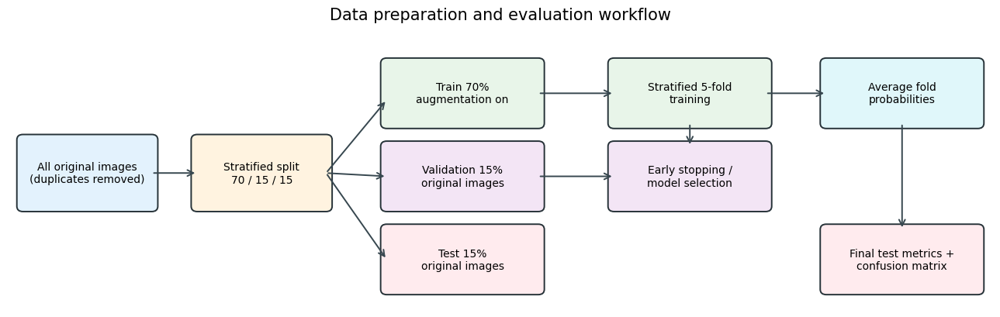

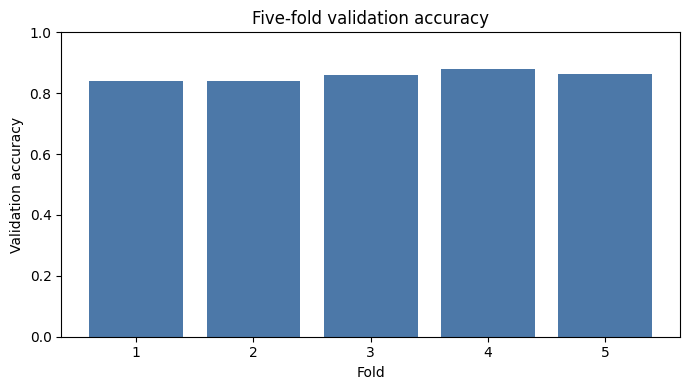

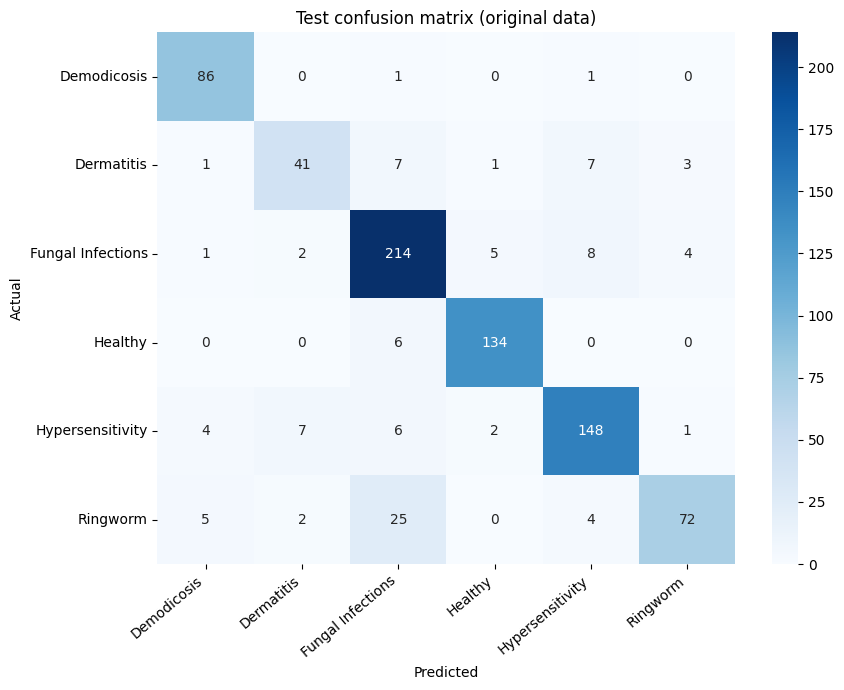

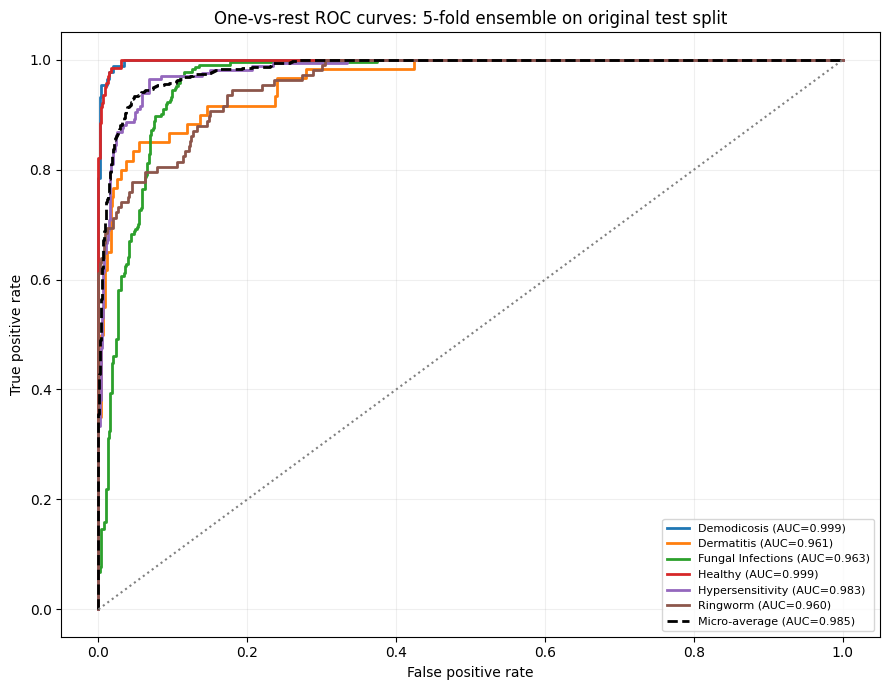

Matthews correlation coefficient (MCC): 0.8395
Macro precision: 0.8710
Macro recall: 0.8466
Macro F1: 0.8545
Test accuracy 95% bootstrap CI: [0.8471 0.8923]
Test MCC 95% bootstrap CI: [0.8107 0.8671]


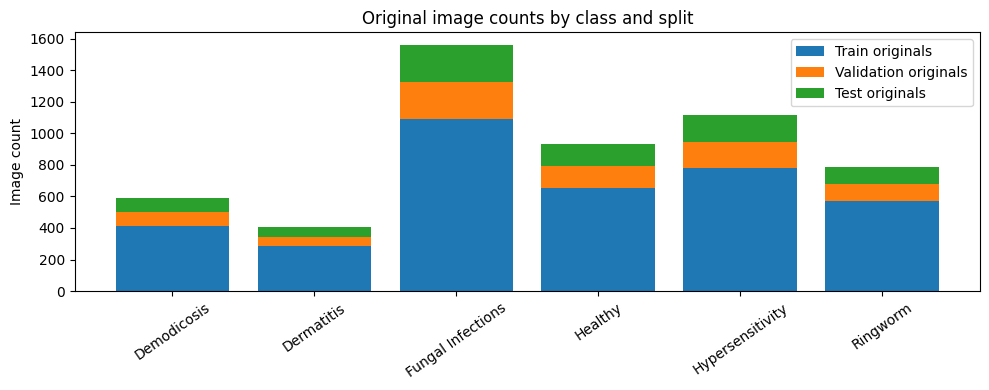

Per-class split counts (train, validation, test):
Demodicosis [412, 88, 88]
Dermatitis [284, 61, 60]
Fungal Infections [1093, 235, 234]
Healthy [652, 140, 140]
Hypersensitivity [780, 167, 168]
Ringworm [570, 107, 108]


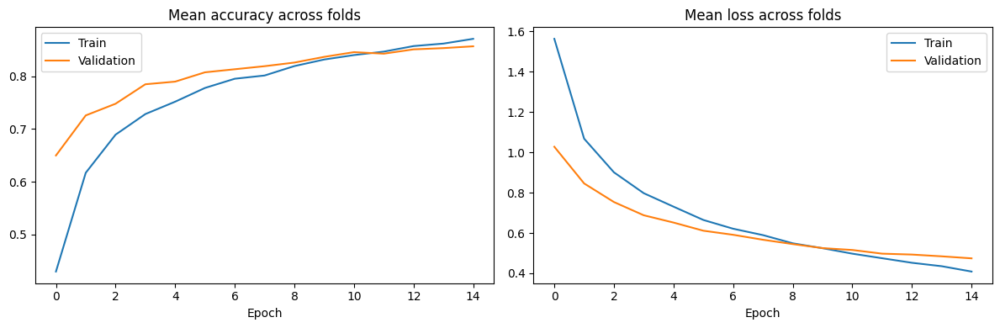

Grad-CAM image: /content/drive/MyDrive/Machine Learning Group 3/Dataset Final/Ringworm/436660568_816714827062296_2603836073731005890_n_jpg.rf.94d417b3859b6016d0514ca9a4976ed4.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step

Prediction: Ringworm (1.00)


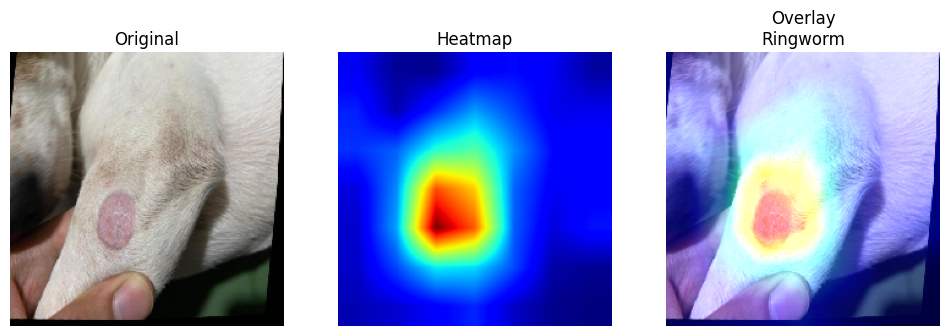

In [ ]:
# ============================================================
# STEP 1 : LOAD DATASET FROM GOOGLE DRIVE
# ============================================================
# Use the final dataset (already combined + segmentation results) from the following link (STEP 2 IN README):
# https://drive.google.com/drive/folders/1DkTKkC-1n2C0c5hb0Bm0hILIqvz6JbKl?usp=sharing
#
# How to use:
# 1. Open the link above
# 2. Click "Add shortcut to Drive"
# 3. Make sure the folder is saved in:
#    /content/drive/MyDrive/Machine Learning Group 3/Dataset Final
#
# EXTRA (Ringworm segmentation):
# 4. Open the shared folder "segmentation_v2" -> "Add shortcut to Drive"
#    so that this path exists:
#    /content/drive/MyDrive/segmentation_v2/roi_images/{train,val,test}
# ============================================================

# --- Connect to Google Drive ---
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# --- Import All Libraries ---
import tensorflow as tf
import numpy as np
import pathlib
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.applications import EfficientNetB0, ResNet50
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

# ============================================================
# DATASET SETUP: split original files first (70/15/15), then augment training only
# ============================================================
import pathlib, hashlib
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_curve, auc, matthews_corrcoef, f1_score, precision_score, recall_score
from tensorflow.keras.applications import EfficientNetB0, ResNet50
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

data_dir = pathlib.Path("/content/drive/MyDrive/Machine Learning Group 3/Dataset Final")
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123
N_SPLITS = 5
EPOCHS = 15
AUTOTUNE = tf.data.AUTOTUNE

# Set to False to run the baseline WITHOUT segmentation ROI (for a fair with/without comparison).
USE_ROI = True

# --- Ringworm segmentation (ROI) settings ---
# Ringworm ROI crops (U-Net VGG segmentation output, folder roi_images/train ONLY) are
# added to the TRAINING set. Validation and test contain original images only.
seg_dir = pathlib.Path("/content/drive/MyDrive/segmentation_v2/roi_images")  # adjust to your shortcut name
RINGWORM_NAME = "Ringworm"  # must match the class folder name in Dataset Final exactly

# Collect image files and remove exact byte duplicates before splitting.
valid_ext = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_names = sorted(p.name for p in data_dir.iterdir() if p.is_dir())
class_to_id = {name: i for i, name in enumerate(class_names)}

if USE_ROI and not seg_dir.exists():
    raise FileNotFoundError(f"ROI folder not found: {seg_dir}")
if RINGWORM_NAME not in class_names:
    raise ValueError(f"Class '{RINGWORM_NAME}' not found in {class_names}")

def list_images(folder):
    return [p for p in sorted(folder.rglob('*')) if p.is_file() and p.suffix.lower() in valid_ext]

seen_hashes = set()
def unique_files(files):
    out = []
    for path in files:
        digest = hashlib.md5(path.read_bytes()).hexdigest()
        if digest not in seen_hashes:
            seen_hashes.add(digest)
            out.append(str(path))
    return out

# --- All classes: original images from Dataset Final, stratified 70/15/15 split ---
all_paths, all_labels = [], []
for name in class_names:
    files = unique_files(list_images(data_dir / name))
    all_paths += files
    all_labels += [class_to_id[name]] * len(files)
all_paths, all_labels = np.asarray(all_paths), np.asarray(all_labels, dtype=np.int32)

train_paths, hold_paths, y_train, y_hold = train_test_split(
    all_paths, all_labels, test_size=0.30, random_state=SEED, stratify=all_labels)
val_paths, test_paths, y_val, y_test = train_test_split(
    hold_paths, y_hold, test_size=0.50, random_state=SEED, stratify=y_hold)

# --- Ringworm segmentation: add ROI crops from roi_images/train to the TRAINING set only ---
rw_id = class_to_id[RINGWORM_NAME]
if USE_ROI:
    rw_roi_train = unique_files(list_images(seg_dir / "train"))
    if len(rw_roi_train) == 0:
        raise ValueError(f"No images found in {seg_dir / 'train'}")
    train_paths = np.concatenate([train_paths, np.asarray(rw_roi_train)])
    y_train = np.concatenate([y_train, np.full(len(rw_roi_train), rw_id, dtype=np.int32)])
    print(f"Added {len(rw_roi_train)} Ringworm ROI images (roi_images/train) to the training set only.")
else:
    print("USE_ROI=False: baseline run without segmentation ROI.")

paths = np.concatenate([train_paths, val_paths, test_paths])
labels = np.concatenate([y_train, y_val, y_test])

num_classes = len(class_names)
if num_classes < 2 or len(paths) == 0:
    raise ValueError(f"No usable class folders/images found in {data_dir}")
print(f"{len(paths)} unique images; {num_classes} classes: {class_names}")
print("Images per class:", {n: int((labels == i).sum()) for n, i in class_to_id.items()})
print(f"Split counts: train={len(train_paths)} ({len(train_paths)/len(paths):.1%}), "
      f"validation={len(val_paths)} ({len(val_paths)/len(paths):.1%}), "
      f"test={len(test_paths)} ({len(test_paths)/len(paths):.1%})")

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return tf.cast(image, tf.float32), label

def make_dataset(file_paths, file_labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((file_paths, file_labels))
    if training:
        ds = ds.shuffle(len(file_paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

val_ds = make_dataset(val_paths, y_val)
test_ds = make_dataset(test_paths, y_test)

# Moderate augmentation is applied inside the model, and is active only in training.
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal", seed=SEED),
    tf.keras.layers.RandomRotation(0.08, seed=SEED),
    tf.keras.layers.RandomZoom(0.10, seed=SEED),
    tf.keras.layers.RandomContrast(0.10, seed=SEED),
], name="train_only_augmentation")

def build_model():
    global effnet_base, resnet_base
    effnet_base = EfficientNetB0(weights='imagenet', include_top=False, input_shape=IMG_SIZE+(3,))
    resnet_base = ResNet50(weights='imagenet', include_top=False, input_shape=IMG_SIZE+(3,))
    effnet_base.trainable = False
    resnet_base.trainable = False
    inputs = tf.keras.Input(shape=IMG_SIZE+(3,), name='input_layer')
    augmented = data_augmentation(inputs)
    x1 = efficientnet_preprocess(augmented)
    x1 = effnet_base(x1, training=False)
    x1 = tf.keras.layers.GlobalAveragePooling2D(name='effnet_gap')(x1)
    x1 = tf.keras.layers.Dropout(0.25, name='effnet_dropout')(x1)
    x2 = resnet_preprocess(augmented)
    x2 = resnet_base(x2, training=False)
    x2 = tf.keras.layers.GlobalAveragePooling2D(name='resnet_gap')(x2)
    x2 = tf.keras.layers.Dropout(0.25, name='resnet_dropout')(x2)
    merged = tf.keras.layers.Concatenate()([x1, x2])
    x = tf.keras.layers.Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4), name='meta_dense_1')(merged)
    x = tf.keras.layers.Dropout(0.35, name='meta_dropout')(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax', name='output_layer')(x)
    model = tf.keras.Model(inputs, outputs, name='Stacking_EfficientNetB0_ResNet50')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# Five-fold stratified CV uses only the 70% training partition. The untouched
# original validation split controls early stopping; test is opened only at final evaluation.
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
fold_models, fold_histories, fold_scores = [], [], []
for fold, (fit_idx, fold_val_idx) in enumerate(skf.split(train_paths, y_train), start=1):
    print(f"\n=== Fold {fold}/{N_SPLITS} ===")
    fold_train_ds = make_dataset(train_paths[fit_idx], y_train[fit_idx], training=True)
    fold_val_ds = make_dataset(train_paths[fold_val_idx], y_train[fold_val_idx])
    model = build_model()
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-6),
    ]
    history = model.fit(fold_train_ds, validation_data=fold_val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=1)
    fold_histories.append(history.history)
    fold_models.append(model)
    score = model.evaluate(fold_val_ds, verbose=0)
    fold_scores.append(score[1])
    print(f"Fold {fold} internal validation accuracy: {score[1]:.4f}")

# Probability averaging across folds reduces variance without training an additional model.
def ensemble_predict(ds):
    probs = [m.predict(ds, verbose=0) for m in fold_models]
    return np.mean(probs, axis=0)
stacked_model = fold_models[int(np.argmax(fold_scores))]  # used by the Grad-CAM section
# Keep Grad-CAM connected to the exact backbone weights of the selected fold.
effnet_base = stacked_model.get_layer('efficientnetb0')
resnet_base = stacked_model.get_layer('resnet50')
pred_val = np.argmax(ensemble_predict(val_ds), axis=1)
print(f"\nMean 5-fold internal validation accuracy: {np.mean(fold_scores):.4f} +/- {np.std(fold_scores):.4f}")
print(f"Ensemble validation accuracy: {accuracy_score(y_val, pred_val):.4f}")

# Final unbiased evaluation on the untouched 15% original test split.
y_true = y_test
y_prob = ensemble_predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)
print("\n=== Test classification report (5-fold ensemble) ===")
print(classification_report(y_true, y_pred, labels=np.arange(num_classes), target_names=class_names, zero_division=0))
print("Test accuracy:", accuracy_score(y_true, y_pred))
cm = confusion_matrix(y_true, y_pred, labels=np.arange(num_classes))

# Diagrams: split/training workflow, fold validation accuracy, and actual test confusion matrix.
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
fig, ax = plt.subplots(figsize=(13, 4.2)); ax.set_xlim(0, 13); ax.set_ylim(0, 4.2); ax.axis('off')
def box(x, y, w, h, label, color):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.08',facecolor=color,edgecolor='#263238',linewidth=1.4))
    ax.text(x+w/2,y+h/2,label,ha='center',va='center',fontsize=10,wrap=True)
def arrow(x1,y1,x2,y2): ax.add_patch(FancyArrowPatch((x1,y1),(x2,y2),arrowstyle='->',mutation_scale=14,color='#37474f',linewidth=1.4))
box(.2,1.55,1.7,1.0,'All original images\n(duplicates removed)','#e3f2fd')
box(2.5,1.55,1.7,1.0,'Stratified split\n70 / 15 / 15','#fff3e0')
box(5,2.8,2.0,.9,'Train 70%\naugmentation on','#e8f5e9')
box(5,1.55,2.0,.9,'Validation 15%\noriginal images','#f3e5f5')
box(5,.3,2.0,.9,'Test 15%\noriginal images','#ffebee')
box(8,2.8,2.0,.9,'Stratified 5-fold\ntraining','#e8f5e9')
box(10.8,2.8,2.0,.9,'Average fold\nprobabilities','#e0f7fa')
box(8,1.55,2.0,.9,'Early stopping /\nmodel selection','#f3e5f5')
box(10.8,.3,2.0,.9,'Final test metrics +\nconfusion matrix','#ffebee')
arrow(1.9,2.05,2.5,2.05); arrow(4.2,2.05,5,3.15); arrow(4.2,2.05,5,2.0); arrow(4.2,2.05,5,.75)
arrow(7,3.25,8,3.25); arrow(10,3.25,10.8,3.25); arrow(7,2.0,8,2.0); arrow(9,2.8,9,2.45); arrow(11.8,2.8,11.8,1.2)
ax.set_title('Data preparation and evaluation workflow',fontsize=15,pad=10); plt.tight_layout(); plt.show()

plt.figure(figsize=(7,4)); plt.bar(np.arange(1,N_SPLITS+1),fold_scores,color='#4c78a8')
plt.ylim(0,1); plt.xticks(np.arange(1,N_SPLITS+1)); plt.ylabel('Validation accuracy'); plt.xlabel('Fold')
plt.title('Five-fold validation accuracy'); plt.tight_layout(); plt.show()

plt.figure(figsize=(9,7)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Test confusion matrix (original data)'); plt.xticks(rotation=40,ha='right'); plt.yticks(rotation=0); plt.tight_layout(); plt.show()

# Multi-class one-vs-rest ROC curves on the untouched original test data.
from sklearn.preprocessing import label_binarize
y_test_bin = label_binarize(y_true, classes=np.arange(num_classes))
plt.figure(figsize=(9, 7))
for class_id, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_test_bin[:, class_id], y_prob[:, class_id])
    class_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{class_name} (AUC={class_auc:.3f})')
# Micro-average summarizes all class decisions.
fpr_micro, tpr_micro, _ = roc_curve(y_test_bin.ravel(), y_prob.ravel())
plt.plot(fpr_micro, tpr_micro, color='black', linestyle='--', lw=2,
         label=f'Micro-average (AUC={auc(fpr_micro, tpr_micro):.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle=':')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('One-vs-rest ROC curves: 5-fold ensemble on original test split')
plt.legend(loc='lower right', fontsize=8); plt.grid(alpha=.2); plt.tight_layout(); plt.show()

# Additional classification metrics. Bootstrap intervals are descriptive 95% CIs
# over test images and do not replace external validation.
mcc = matthews_corrcoef(y_true, y_pred)
print(f'Matthews correlation coefficient (MCC): {mcc:.4f}')
print(f"Macro precision: {precision_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro recall: {recall_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro F1: {f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
rng = np.random.default_rng(SEED)
boot_acc, boot_mcc = [], []
for _ in range(1000):
    idx = rng.integers(0, len(y_true), len(y_true))
    if len(np.unique(y_true[idx])) > 1:
        boot_acc.append(accuracy_score(y_true[idx], y_pred[idx]))
        boot_mcc.append(matthews_corrcoef(y_true[idx], y_pred[idx]))
print('Test accuracy 95% bootstrap CI:', np.percentile(boot_acc, [2.5, 97.5]).round(4))
print('Test MCC 95% bootstrap CI:', np.percentile(boot_mcc, [2.5, 97.5]).round(4))

# Show original-image counts by class for each untouched split.
distribution = np.column_stack([
    np.bincount(y_train, minlength=num_classes),
    np.bincount(y_val, minlength=num_classes),
    np.bincount(y_test, minlength=num_classes)])
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(class_names, distribution[:, 0], label='Train originals')
ax.bar(class_names, distribution[:, 1], bottom=distribution[:, 0], label='Validation originals')
ax.bar(class_names, distribution[:, 2], bottom=distribution[:, 0] + distribution[:, 1], label='Test originals')
ax.set_ylabel('Image count'); ax.set_title('Original image counts by class and split')
ax.tick_params(axis='x', rotation=35); ax.legend(); plt.tight_layout(); plt.show()
print('Per-class split counts (train, validation, test):')
for i, name in enumerate(class_names): print(name, distribution[i].tolist())

# Average fold learning curves for training/validation diagrams.
common_epochs = min(len(h['accuracy']) for h in fold_histories)
mean_train_acc = np.mean([h['accuracy'][:common_epochs] for h in fold_histories], axis=0)
mean_val_acc = np.mean([h['val_accuracy'][:common_epochs] for h in fold_histories], axis=0)
mean_train_loss = np.mean([h['loss'][:common_epochs] for h in fold_histories], axis=0)
mean_val_loss = np.mean([h['val_loss'][:common_epochs] for h in fold_histories], axis=0)
plt.figure(figsize=(12,4))
plt.subplot(1,2,1); plt.plot(mean_train_acc,label='Train'); plt.plot(mean_val_acc,label='Validation'); plt.title('Mean accuracy across folds'); plt.xlabel('Epoch'); plt.legend()
plt.subplot(1,2,2); plt.plot(mean_train_loss,label='Train'); plt.plot(mean_val_loss,label='Validation'); plt.title('Mean loss across folds'); plt.xlabel('Epoch'); plt.legend()
plt.tight_layout(); plt.show()

# ----------------------------- Grad-CAM Manual Input -----------------------------

import cv2

# Convert tensor to uint8 (for visualization)
def tensor_to_uint8(img_tensor):
    img = img_tensor.numpy()
    if img.max() <= 1.0:
        img = (img * 255).astype('uint8')
    return img.astype('uint8')

# Grad-CAM function for ensemble model
def gradcam_for_ensemble(stack_model, effnet_base, resnet_base, img, class_index=None):

    img_tensor = tf.expand_dims(img, axis=0)

    # Preprocessing based on each model
    x_eff = efficientnet_preprocess(tf.cast(img_tensor, tf.float32))
    x_res = resnet_preprocess(tf.cast(img_tensor, tf.float32))

    # Retrieve layers based on training architecture
    effnet_gap = stack_model.get_layer('effnet_gap')
    effnet_dropout = stack_model.get_layer('effnet_dropout')
    resnet_gap = stack_model.get_layer('resnet_gap')
    resnet_dropout = stack_model.get_layer('resnet_dropout')
    meta_dense = stack_model.get_layer('meta_dense_1')
    meta_dropout = stack_model.get_layer('meta_dropout')
    output_layer = stack_model.get_layer('output_layer')

    with tf.GradientTape(persistent=True) as tape:
        # Forward pass
        act1 = effnet_base(x_eff, training=False)
        act2 = resnet_base(x_res, training=False)

        tape.watch(act1)
        tape.watch(act2)

        # Must match training pipeline exactly
        gap1 = effnet_gap(act1)
        gap1 = effnet_dropout(gap1, training=False)

        gap2 = resnet_gap(act2)
        gap2 = resnet_dropout(gap2, training=False)

        concat = tf.concat([gap1, gap2], axis=-1)

        x = meta_dense(concat)
        x = meta_dropout(x, training=False)
        preds = output_layer(x)

        # Use predicted class if not specified
        if class_index is None:
            class_index = tf.argmax(preds[0])

        class_score = preds[:, class_index]

    # Compute gradients
    grads1 = tape.gradient(class_score, act1)
    grads2 = tape.gradient(class_score, act2)

    # Compute weights
    weights1 = tf.reduce_mean(grads1, axis=(1,2))
    weights2 = tf.reduce_mean(grads2, axis=(1,2))

    # Compute CAM
    cam1 = tf.reduce_sum(tf.multiply(act1, weights1[:, None, None, :]), axis=-1)[0].numpy()
    cam2 = tf.reduce_sum(tf.multiply(act2, weights2[:, None, None, :]), axis=-1)[0].numpy()

    # Normalize heatmap
    heatmap = (cam1 + cam2) / 2
    heatmap = np.maximum(heatmap, 0)
    heatmap = heatmap / (heatmap.max() + 1e-8)
    heatmap = cv2.resize(heatmap, (IMG_SIZE[1], IMG_SIZE[0]))

    return heatmap, preds.numpy()[0], int(class_index.numpy() if hasattr(class_index, 'numpy') else class_index)

# Overlay heatmap onto image
def overlay_heatmap_on_image(img, heatmap):
    heatmap = np.uint8(255 * heatmap)
    heatmap_color = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(img, 1, heatmap_color, 0.5, 0)
    return heatmap_color, overlay

# ----------------------------- USER IMAGE INPUT -----------------------------
# Default: first Ringworm image (original, not ROI) from the untouched test split.
# To use a specific file, replace with: img_path = "/content/drive/MyDrive/.../your_image.jpg"
img_path = test_paths[y_test == class_to_id[RINGWORM_NAME]][0]
print("Grad-CAM image:", img_path)

img = tf.keras.preprocessing.image.load_img(img_path, target_size=IMG_SIZE)
img_array = tf.keras.preprocessing.image.img_to_array(img)
img_uint8 = img_array.astype("uint8")

# Prediction
pred = stacked_model.predict(tf.expand_dims(img_array, axis=0))
pred_class = np.argmax(pred)
pred_conf = pred[0][pred_class]

print(f"\nPrediction: {class_names[pred_class]} ({pred_conf:.2f})")

# Grad-CAM
heatmap, _, _ = gradcam_for_ensemble(stacked_model, effnet_base, resnet_base, img_array)

heatmap_rgb, overlay = overlay_heatmap_on_image(img_uint8, heatmap)

# Visualization
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(img_uint8)
plt.title("Original")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(heatmap, cmap='jet')
plt.title("Heatmap")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(overlay)
plt.title(f"Overlay\n{class_names[pred_class]}")
plt.axis('off')

plt.show()

Demodicosis: IMG_5298_jpeg_jpg.rf.80f8b221bee338f07cadbbbb6a26c165.jpg
Dermatitis: seborrheic_dermatitis_4935_10_600_webp_jpg.rf.56a373e731a6bc8953b311d1f7575c6f.jpg
Fungal Infections: FUNGAL-INFECTION_011_jpg.rf.ab987a16deee5f036759edf5918d1405.jpg
Healthy: Copy of Copy of healthy_394_jpg.rf.ad612a4851f9c1d2fc2b0b2a77e1c733.jpg
Hypersensitivity: hypersensitivity_308_jpg.rf.e8bd8a23d37de000be1ce25532b33931.jpg
Ringworm: NEWR9_jpeg_jpg.rf.9a267aa73df4de9d623acae24d65c2d0.jpg


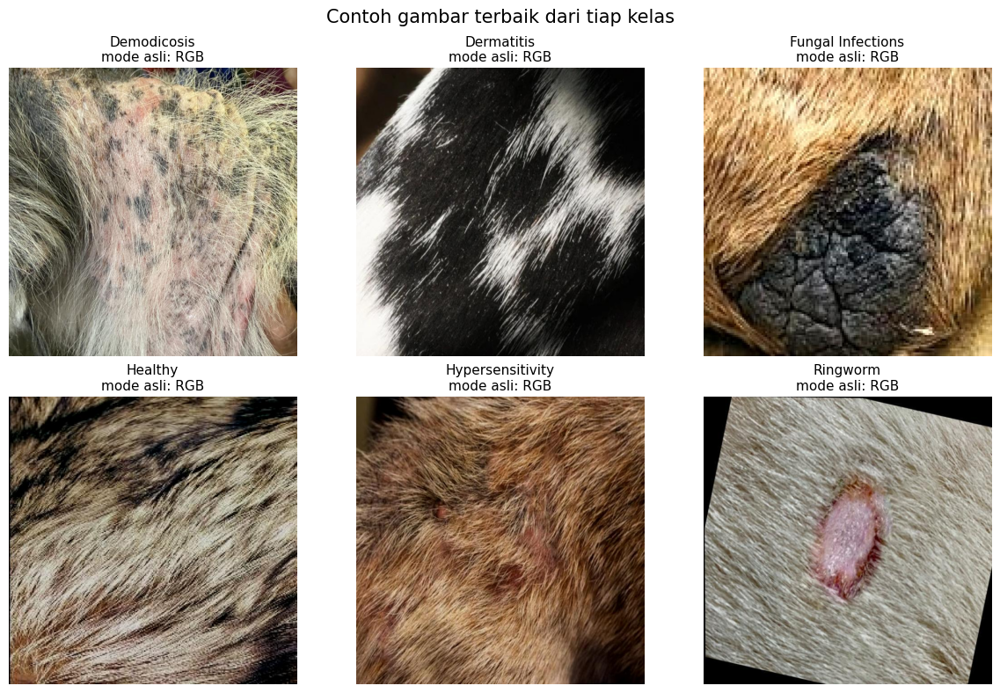

In [ ]:
# Cell baru: contoh gambar terbaik dari tiap kelas (mandiri)
import pathlib, cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

data_dir = pathlib.Path("/content/drive/MyDrive/Machine Learning Group 3/Dataset Final")
valid_ext = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SEED = 123
MAX_CANDIDATES = 200      # jumlah gambar yang dinilai per kelas (biar cepat)
MIN_SIDE = 224            # abaikan gambar yang sisi terpendeknya lebih kecil dari ini

class_names = sorted(p.name for p in data_dir.iterdir() if p.is_dir())
num_classes = len(class_names)
rng_vis = np.random.default_rng(SEED)

def quality_score(path):
    img = Image.open(path)
    w, h = img.size
    if min(w, h) < MIN_SIDE:
        return None
    gray = np.asarray(img.convert("L").resize((256, 256)), dtype=np.float32)
    sharp = cv2.Laplacian(gray, cv2.CV_32F).var()          # makin besar makin tajam
    mean_b = gray.mean()
    if mean_b < 50 or mean_b > 210:                        # terlalu gelap / terang
        return None
    contrast = gray.std()
    return sharp * 0.7 + contrast * 0.3

best_files = {}
for name in class_names:
    files = [p for p in (data_dir / name).rglob('*')
             if p.is_file() and p.suffix.lower() in valid_ext]
    if len(files) > MAX_CANDIDATES:
        files = [files[i] for i in rng_vis.choice(len(files), MAX_CANDIDATES, replace=False)]
    scored = []
    for f in files:
        try:
            s = quality_score(f)
            if s is not None:
                scored.append((s, f))
        except Exception:
            continue
    scored.sort(key=lambda x: x[0], reverse=True)
    best_files[name] = scored[0][1] if scored else files[0]
    print(f"{name}: {best_files[name].name}")

# (Opsional) kalau mau pilih manual, isi nama file di sini lalu jalankan ulang:
# MANUAL = {"Fungal infection": "nama_file.jpg"}
# for k, v in MANUAL.items():
#     best_files[k] = next((data_dir / k).rglob(v))

n_cols = 3
n_rows = int(np.ceil(num_classes / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
axes = np.array(axes).reshape(-1)

for i, name in enumerate(class_names):
    img = Image.open(best_files[name])
    mode = img.mode
    if mode in ("P", "CMYK", "I;16", "I", "F"):
        img = img.convert("RGB")
    if img.mode == "L":
        axes[i].imshow(img, cmap="gray")
    else:
        axes[i].imshow(img)
    axes[i].set_title(f"{name}\nmode asli: {mode}", fontsize=11)
    axes[i].axis('off')

for ax in axes[num_classes:]:
    ax.axis('off')

plt.suptitle("Contoh gambar terbaik dari tiap kelas", fontsize=15)
plt.tight_layout()
plt.show()

In [1]:
import sys, tensorflow as tf, numpy as np, sklearn, cv2, PIL, matplotlib, seaborn as sns
print("Python", sys.version.split()[0])
for n, m in [("TensorFlow", tf), ("NumPy", np), ("scikit-learn", sklearn), ("OpenCV", cv2),
             ("Pillow", PIL), ("Matplotlib", matplotlib), ("Seaborn", sns)]:
    print(n, m.__version__)

Python 3.13.16
TensorFlow 2.21.0
NumPy 2.1.3
scikit-learn 1.6.1
OpenCV 4.14.0
Pillow 11.3.0
Matplotlib 3.10.0
Seaborn 0.13.2


In [ ]:
# ============================================================
# SINGLE CELL: retrain 5-fold Ensemble (EffNetB0+ResNet50) & 5-fold ResNet50
# + McNemar + bootstrap CI + paired bootstrap. Split identik (SEED=123).
# ============================================================
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import hashlib, pathlib
import numpy as np
import tensorflow as tf
from scipy.stats import binomtest, chi2
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (classification_report, accuracy_score, matthews_corrcoef,
                             confusion_matrix)
from tensorflow.keras.applications import EfficientNetB0, ResNet50
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

# ---------------- Konfigurasi ----------------
data_dir = pathlib.Path('/content/drive/MyDrive/Machine Learning Group 3/Dataset Final')
OUT = '/content/drive/MyDrive/Machine Learning Group 3/'
IMG_SIZE, BATCH_SIZE, SEED, N_SPLITS, EPOCHS = (224, 224), 32, 123, 5, 15
AUTOTUNE = tf.data.AUTOTUNE
tf.keras.utils.set_random_seed(SEED)

# ---------------- Dataset & split (identik dengan kode utama) ----------------
valid_ext = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
class_names = sorted(p.name for p in data_dir.iterdir() if p.is_dir())
class_to_id = {n: i for i, n in enumerate(class_names)}
seen, paths, labels = set(), [], []
for name in class_names:
    for path in sorted((data_dir / name).rglob('*')):
        if path.is_file() and path.suffix.lower() in valid_ext:
            h = hashlib.md5(path.read_bytes()).hexdigest()
            if h not in seen:
                seen.add(h); paths.append(str(path)); labels.append(class_to_id[name])
paths, labels = np.asarray(paths), np.asarray(labels, dtype=np.int32)
num_classes = len(class_names)
print(f'{len(paths)} unique images; {num_classes} classes: {class_names}')

train_paths, hold_paths, y_train, y_hold = train_test_split(
    paths, labels, test_size=0.30, random_state=SEED, stratify=labels)
val_paths, test_paths, y_val, y_test = train_test_split(
    hold_paths, y_hold, test_size=0.50, random_state=SEED, stratify=y_hold)
print(f'train={len(train_paths)}, val={len(val_paths)}, test={len(test_paths)}')

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    return tf.cast(img, tf.float32), label

def make_dataset(fp, fl, training=False):
    ds = tf.data.Dataset.from_tensor_slices((fp, fl))
    if training:
        ds = ds.shuffle(len(fp), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

test_ds = make_dataset(test_paths, y_test)   # tidak di-shuffle -> urutan = y_test

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal', seed=SEED),
    tf.keras.layers.RandomRotation(0.08, seed=SEED),
    tf.keras.layers.RandomZoom(0.10, seed=SEED),
    tf.keras.layers.RandomContrast(0.10, seed=SEED),
], name='train_only_augmentation')

# ---------------- Model ----------------
def build_ensemble():
    eff = EfficientNetB0(weights='imagenet', include_top=False, input_shape=IMG_SIZE+(3,))
    res = ResNet50(weights='imagenet', include_top=False, input_shape=IMG_SIZE+(3,))
    eff.trainable = False; res.trainable = False
    inp = tf.keras.Input(shape=IMG_SIZE+(3,))
    aug = data_augmentation(inp)
    x1 = eff(efficientnet_preprocess(aug), training=False)
    x1 = tf.keras.layers.Dropout(0.25)(tf.keras.layers.GlobalAveragePooling2D()(x1))
    x2 = res(resnet_preprocess(aug), training=False)
    x2 = tf.keras.layers.Dropout(0.25)(tf.keras.layers.GlobalAveragePooling2D()(x2))
    x = tf.keras.layers.Concatenate()([x1, x2])
    x = tf.keras.layers.Dense(256, activation='relu',
                              kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.Dropout(0.35)(x)
    out = tf.keras.layers.Dense(num_classes, activation='softmax')(x)
    m = tf.keras.Model(inp, out, name='Ensemble_EffNetB0_ResNet50')
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

def build_resnet():
    res = ResNet50(weights='imagenet', include_top=False, input_shape=IMG_SIZE+(3,))
    res.trainable = False
    inp = tf.keras.Input(shape=IMG_SIZE+(3,))
    x = res(resnet_preprocess(data_augmentation(inp)), training=False)
    x = tf.keras.layers.Dropout(0.25)(tf.keras.layers.GlobalAveragePooling2D()(x))
    x = tf.keras.layers.Dense(256, activation='relu',
                              kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.Dropout(0.35)(x)
    out = tf.keras.layers.Dense(num_classes, activation='softmax')(x)
    m = tf.keras.Model(inp, out, name='ResNet50_standalone')
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

def run_5fold(builder, tag):
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    models, scores = [], []
    for fold, (fit_idx, val_idx) in enumerate(skf.split(train_paths, y_train), start=1):
        print(f'\n=== {tag} fold {fold}/{N_SPLITS} ===')
        tr = make_dataset(train_paths[fit_idx], y_train[fit_idx], training=True)
        va = make_dataset(train_paths[val_idx], y_train[val_idx])
        m = builder()
        cbs = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3,
                                                restore_best_weights=True),
               tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3,
                                                    patience=2, min_lr=1e-6)]
        m.fit(tr, validation_data=va, epochs=EPOCHS, callbacks=cbs, verbose=1)
        s = m.evaluate(va, verbose=0)[1]
        print(f'{tag} fold {fold} internal val acc: {s:.4f}')
        models.append(m); scores.append(s)
    probs = np.mean([m.predict(test_ds, verbose=0) for m in models], axis=0)
    return probs, np.array(scores)

# ---------------- Training ----------------
ens_prob, ens_scores = run_5fold(build_ensemble, 'Ensemble')
res_prob, res_scores = run_5fold(build_resnet,  'ResNet50')
pred_ens, pred_res = ens_prob.argmax(1), res_prob.argmax(1)

# Simpan supaya tidak perlu train ulang kalau runtime putus
np.savez(OUT + 'final_predictions.npz', y_test=y_test, ens_prob=ens_prob, res_prob=res_prob,
         ens_scores=ens_scores, res_scores=res_scores, test_paths=test_paths)

# ---------------- Hasil per model ----------------
for tag, p in [('Ensemble', pred_ens), ('ResNet50', pred_res)]:
    print(f'\n=== {tag} test report ===')
    print(classification_report(y_test, p, labels=np.arange(num_classes),
                                target_names=class_names, zero_division=0))
print(f'\nMean 5-fold val acc  Ensemble: {ens_scores.mean()*100:.2f} ± {ens_scores.std()*100:.2f} '
      f'(range {ens_scores.min()*100:.2f}-{ens_scores.max()*100:.2f})')
print(f'Mean 5-fold val acc  ResNet50: {res_scores.mean()*100:.2f} ± {res_scores.std()*100:.2f}')

# ---------------- Bootstrap CI (akurasi & MCC) ----------------
n = len(y_test)
rng = np.random.default_rng(SEED)
B = 1000
def boot_ci(pred):
    acc, mcc = [], []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        acc.append(accuracy_score(y_test[idx], pred[idx]))
        mcc.append(matthews_corrcoef(y_test[idx], pred[idx]))
    return np.percentile(acc, [2.5, 97.5]), np.percentile(mcc, [2.5, 97.5])

for tag, p in [('Ensemble', pred_ens), ('ResNet50', pred_res)]:
    a_ci, m_ci = boot_ci(p)
    print(f'{tag}: acc {accuracy_score(y_test, p)*100:.2f}% (95% CI {a_ci[0]*100:.1f}-{a_ci[1]*100:.1f}), '
          f'MCC {matthews_corrcoef(y_test, p):.3f} (95% CI {m_ci[0]:.3f}-{m_ci[1]:.3f})')

# ---------------- McNemar ----------------
eo, ro = (pred_ens == y_test), (pred_res == y_test)
a = int(np.sum(eo & ro)); b = int(np.sum(eo & ~ro))
c = int(np.sum(~eo & ro)); d = int(np.sum(~eo & ~ro))
print(f'\nN={n} | Ensemble {eo.mean():.2%} | ResNet50 {ro.mean():.2%}')
print('                 ResNet benar | ResNet salah')
print(f'Ensemble benar :   {a:6d}     |   {b:6d}')
print(f'Ensemble salah :   {c:6d}     |   {d:6d}')

n_disc = b + c
p_exact = binomtest(b, n_disc, 0.5).pvalue if n_disc else 1.0
stat = (abs(b - c) - 1) ** 2 / n_disc if n_disc else 0.0
p_chi = chi2.sf(stat, 1)
print(f'\nMcNemar: b={b}, c={c}, chi2={stat:.3f}, p(chi2)={p_chi:.4g}, p(exact)={p_exact:.4g}')

# ---------------- Paired bootstrap selisih akurasi ----------------
diffs = []
for _ in range(10000):
    idx = rng.integers(0, n, n)
    diffs.append(eo[idx].mean() - ro[idx].mean())
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f'Selisih akurasi: {(eo.mean()-ro.mean())*100:.2f} poin '
      f'(95% paired bootstrap CI {lo*100:.2f} sampai {hi*100:.2f})')

# ---------------- Kalimat untuk response letter ----------------
sig = p_exact < 0.05
p_txt = 'p < 0.001' if p_chi < 0.001 else f'p = {p_chi:.3f}'
a_ci, m_ci = boot_ci(pred_ens)
print('\n=== KALIMAT RESPONSE LETTER ===')
print(f"The ensemble reaches {eo.mean()*100:.1f}% accuracy on the {n} test images versus "
      f"{ro.mean()*100:.1f}% for ResNet50, a gain of {(eo.mean()-ro.mean())*100:.1f} percentage points. "
      f"Bootstrap 95% CIs over test images (1,000 resamples): ensemble accuracy "
      f"{eo.mean()*100:.1f}% ({a_ci[0]*100:.1f}-{a_ci[1]*100:.1f}%), MCC {matthews_corrcoef(y_test, pred_ens):.3f} "
      f"({m_ci[0]:.3f}-{m_ci[1]:.3f}). A McNemar's test on the paired predictions gave "
      f"χ² = {stat:.2f}, {p_txt} (exact binomial p = {p_exact:.3g}); {b} images were correctly classified only "
      f"by the ensemble and {c} only by ResNet50, indicating that the improvement is "
      f"{'statistically significant' if sig else 'consistent but not statistically significant'} at α = 0.05. "
      f"The paired bootstrap 95% CI of the accuracy difference was [{lo*100:.1f}, {hi*100:.1f}] percentage points. "
      f"Stratified five-fold cross-validation within the training partition gave a mean validation accuracy of "
      f"{ens_scores.mean()*100:.2f}% ± {ens_scores.std()*100:.2f}% "
      f"(fold range {ens_scores.min()*100:.2f}-{ens_scores.max()*100:.2f}%).")

Mounted at /content/drive
5319 unique images; 6 classes: ['Demodicosis', 'Dermatitis', 'Fungal Infections', 'Healthy', 'Hypersensitivity', 'Ringworm']
train=3723, val=798, test=798

=== Ensemble fold 1/5 ===
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 53s 320ms/step - accuracy: 0.4238 - loss: 1.6192 - val_accuracy: 0.6430 - val_loss: 1.0458 - learning_rate: 1.0000e-04
Epoch 2/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 24s 254ms/step - accuracy: 0.6172 - loss: 1.0834 - val_accuracy: 0.7181 - val_loss: 0.8709 - learning_rate: 1.0000e-04
Epoch 3/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 25s 264ms/step - accuracy: 0.7005 - loss: 0.9024 - val_accuracy: 0.7745 - val_loss: 0.7523 - learning_rate: 1.0000e-04
Epoch 4/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 267ms/step - accuracy: 0.7243 - loss: 0.8017 - val_accuracy: 0.7960 - val_loss: 0.6984 - learning_rate: 1.0000e-04
Epoch 5/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 26s 272ms/step - accurac

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

=== Ensemble | acc = 0.8697 ===
  Demodicosis          AUC = 0.999
  Dermatitis           AUC = 0.959
  Fungal Infections    AUC = 0.965
  Healthy              AUC = 0.999
  Hypersensitivity     AUC = 0.980
  Ringworm             AUC = 0.967
  Micro-average        AUC = 0.985
  Macro-average        AUC = 0.978

=== ResNet50 | acc = 0.8321 ===
  Demodicosis          AUC = 0.996
  Dermatitis           AUC = 0.937
  Fungal Infections    AUC = 0.951
  Healthy              AUC = 0.997
  Hypersensitivity     AUC = 0.969
  Ringworm             AUC = 0.960
  Micro-average        AUC = 0.977
  Macro-average        AUC = 0.968

--- LaTeX: tabel AUC ---
Disease Class & ResNet50 & Ensemble \\ \hline
Demodicosis & 0.996 & \textbf{0.999} \\
Dermatitis & 0.937 & \textbf{0.959} \\
Fungal Infections & 0.951 & \textbf{0.965} \\
Healthy & 0.997 & \textbf{0.999} \\
Hypersensiti

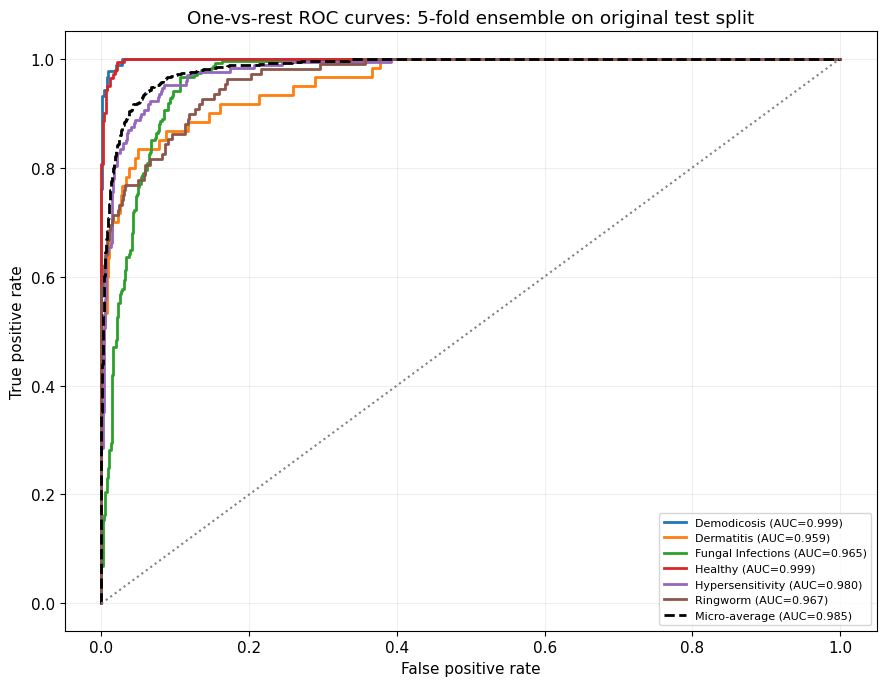

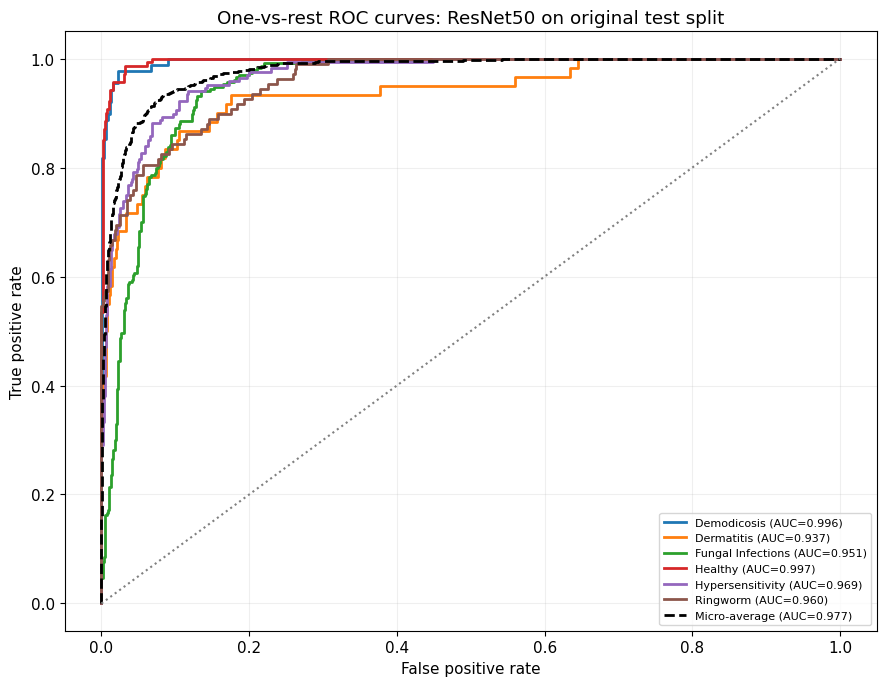

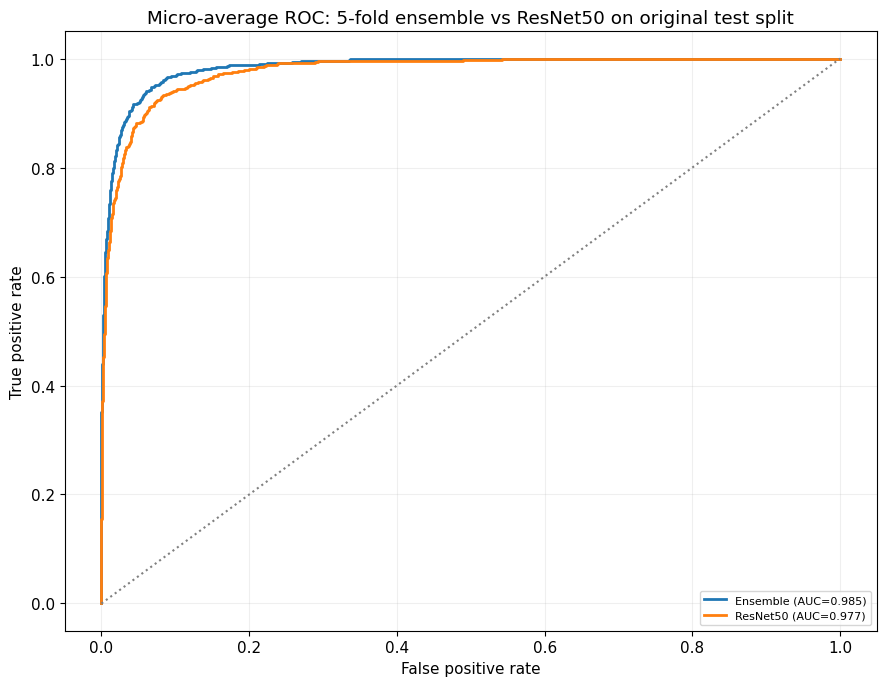

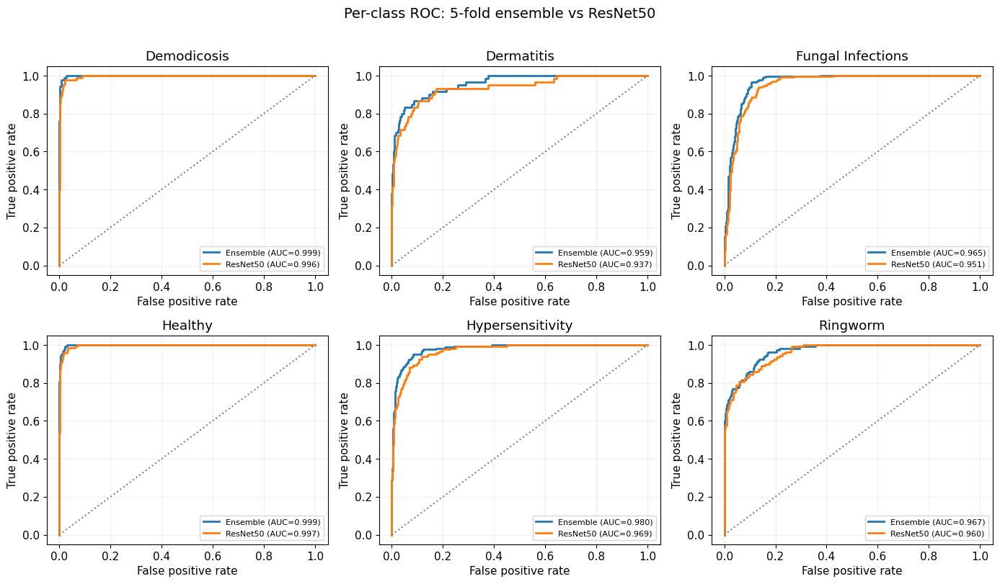


Confusion matrix Ensemble:
 [[ 86   0   1   0   1   0]
 [  1  40   7   1   9   2]
 [  2   1 210   6  12   3]
 [  0   0   5 135   0   0]
 [  3   6   7   1 148   3]
 [  5   1  23   0   4  75]]


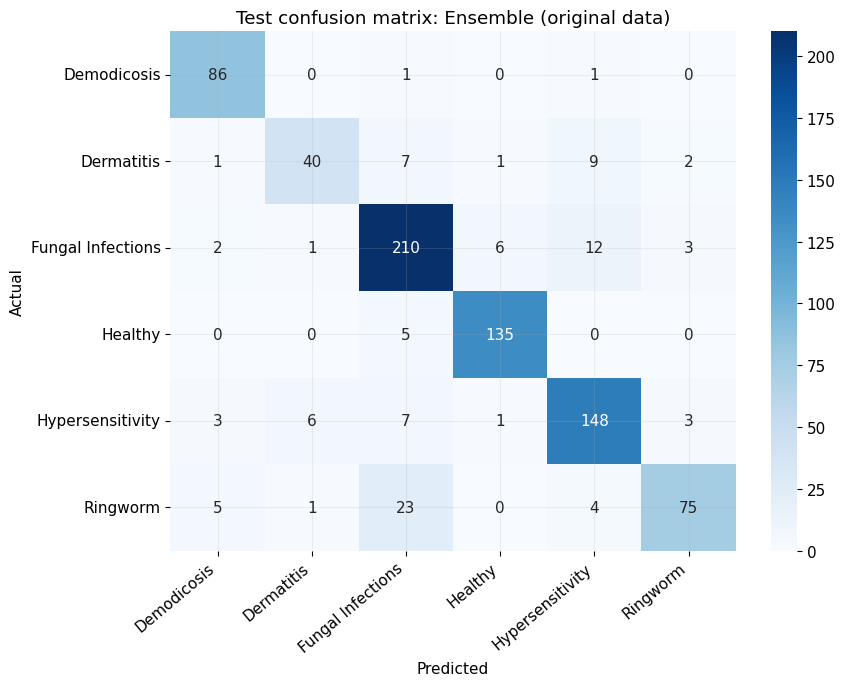

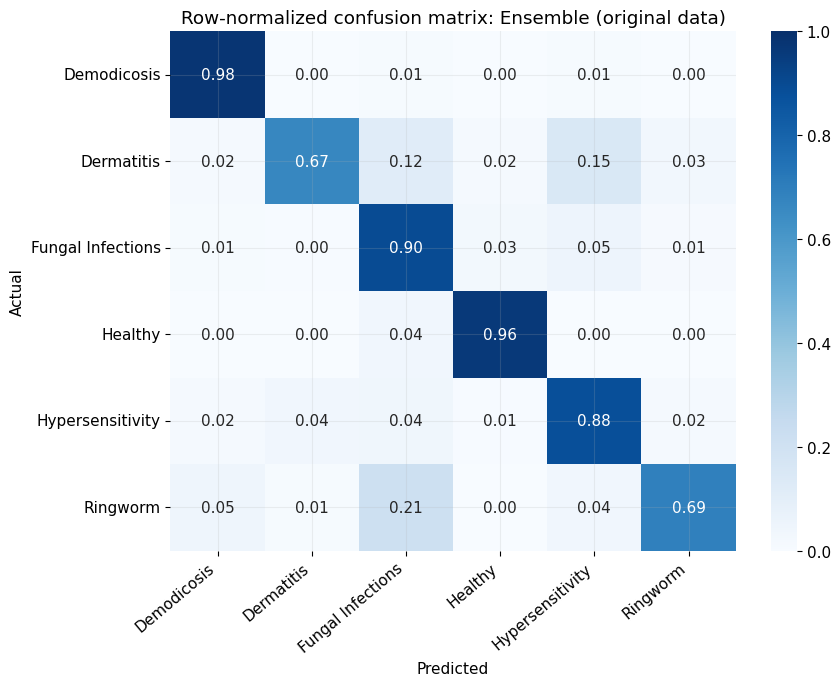


Confusion matrix ResNet50:
 [[ 84   0   2   0   2   0]
 [  1  35   8   1  13   2]
 [  4   1 204   7  15   3]
 [  0   0   8 132   0   0]
 [  4   6  12   2 142   2]
 [  5   3  28   0   5  67]]


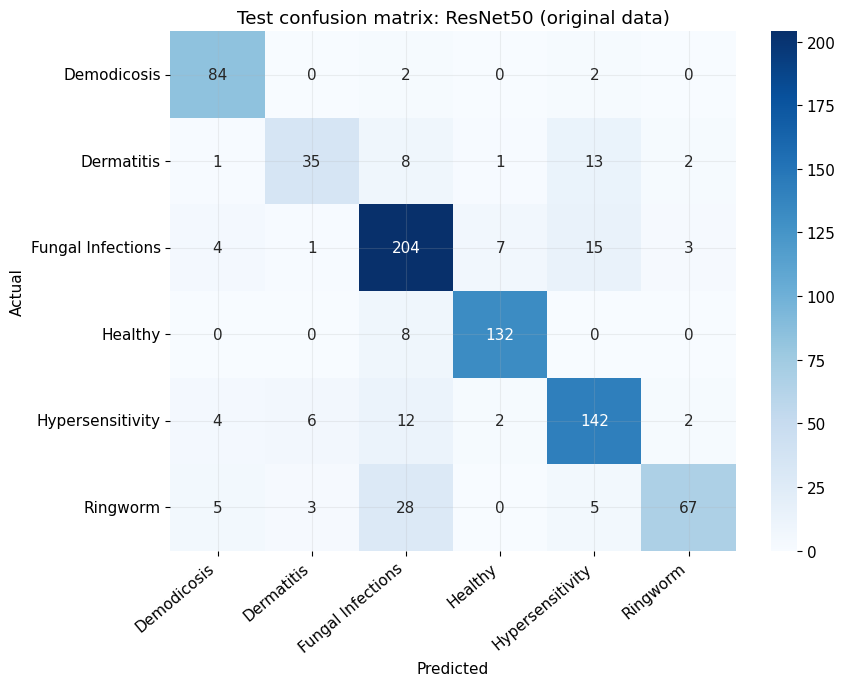

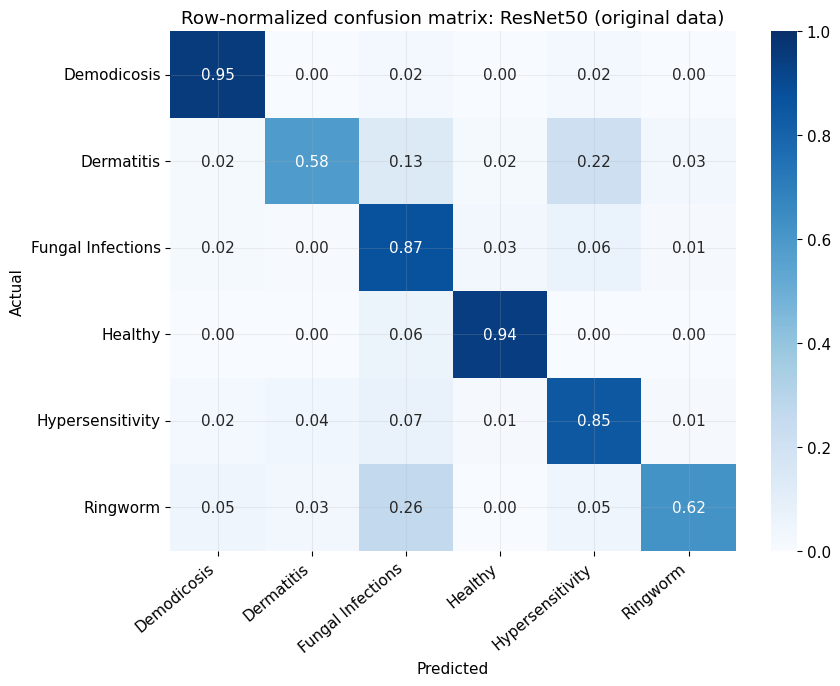


Semua gambar tersimpan di: /content/drive/MyDrive/Machine Learning Group 3/figures/
['confusion_ensemble.pdf', 'confusion_ensemble.png', 'confusion_ensemble_normalized.pdf', 'confusion_ensemble_normalized.png', 'confusion_resnet50.pdf', 'confusion_resnet50.png', 'confusion_resnet50_normalized.pdf', 'confusion_resnet50_normalized.png', 'roc_comparison_micro.pdf', 'roc_comparison_micro.png', 'roc_ensemble.pdf', 'roc_ensemble.png', 'roc_per_class_grid.pdf', 'roc_per_class_grid.png', 'roc_resnet50.pdf', 'roc_resnet50.png']


In [ ]:
# ============================================================
# FULL: AUC + ROC + Confusion Matrix untuk Ensemble & ResNet50 (run kedua)
# Memuat dari final_predictions.npz, tanpa training ulang.
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import pathlib, os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, roc_auc_score, confusion_matrix, accuracy_score
from sklearn.preprocessing import label_binarize

OUT = '/content/drive/MyDrive/Machine Learning Group 3/'
FIG = OUT + 'figures/'
os.makedirs(FIG, exist_ok=True)
data_dir = pathlib.Path(OUT + 'Dataset Final')

d = np.load(OUT + 'final_predictions.npz', allow_pickle=True)
y_test = d['y_test']
probs = {'Ensemble': d['ens_prob'], 'ResNet50': d['res_prob']}
titles = {
    'Ensemble': 'One-vs-rest ROC curves: 5-fold ensemble on original test split',
    'ResNet50': 'One-vs-rest ROC curves: ResNet50 on original test split',
}

class_names = sorted(p.name for p in data_dir.iterdir() if p.is_dir())
K = len(class_names)
assert K == probs['Ensemble'].shape[1], "Jumlah kelas tidak cocok dengan prediksi"
y_bin = label_binarize(y_test, classes=np.arange(K))

def save(name):
    plt.savefig(FIG + name + '.png', dpi=300, bbox_inches='tight')
    plt.savefig(FIG + name + '.pdf', bbox_inches='tight')

# ---------------- 1. AUC per kelas + micro + macro ----------------
auc_table = {}
for model, p in probs.items():
    per_class = [roc_auc_score(y_bin[:, k], p[:, k]) for k in range(K)]
    fpr_mi, tpr_mi, _ = roc_curve(y_bin.ravel(), p.ravel())
    auc_table[model] = {'per_class': per_class,
                        'micro': auc(fpr_mi, tpr_mi),
                        'macro': float(np.mean(per_class))}
    print(f'\n=== {model} | acc = {accuracy_score(y_test, p.argmax(1)):.4f} ===')
    for k, name in enumerate(class_names):
        print(f'  {name:<20} AUC = {per_class[k]:.3f}')
    print(f'  {"Micro-average":<20} AUC = {auc_table[model]["micro"]:.3f}')
    print(f'  {"Macro-average":<20} AUC = {auc_table[model]["macro"]:.3f}')

print('\n--- LaTeX: tabel AUC ---')
print('Disease Class & ResNet50 & Ensemble \\\\ \\hline')
for k, name in enumerate(class_names):
    print(f'{name} & {auc_table["ResNet50"]["per_class"][k]:.3f} & '
          f'\\textbf{{{auc_table["Ensemble"]["per_class"][k]:.3f}}} \\\\')
print('\\hline')
print(f'Micro-average & {auc_table["ResNet50"]["micro"]:.3f} & \\textbf{{{auc_table["Ensemble"]["micro"]:.3f}}} \\\\')
print(f'Macro-average & {auc_table["ResNet50"]["macro"]:.3f} & \\textbf{{{auc_table["Ensemble"]["macro"]:.3f}}} \\\\ \\hline')

# ---------------- 2. ROC per model (gaya & judul sama dengan gambar asli) ----------------
for model, p in probs.items():
    plt.figure(figsize=(9, 7))
    for k, cname in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_bin[:, k], p[:, k])
        plt.plot(fpr, tpr, lw=2, label=f'{cname} (AUC={auc(fpr, tpr):.3f})')
    fpr_mi, tpr_mi, _ = roc_curve(y_bin.ravel(), p.ravel())
    plt.plot(fpr_mi, tpr_mi, color='black', linestyle='--', lw=2,
             label=f'Micro-average (AUC={auc_table[model]["micro"]:.3f})')
    plt.plot([0, 1], [0, 1], color='gray', linestyle=':')
    plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
    plt.title(titles[model])
    plt.legend(loc='lower right', fontsize=8); plt.grid(alpha=.2)
    plt.tight_layout(); save(f'roc_{model.lower()}'); plt.show()

# ---------------- 3. Perbandingan micro-average ----------------
plt.figure(figsize=(9, 7))
for model, p in probs.items():
    fpr_mi, tpr_mi, _ = roc_curve(y_bin.ravel(), p.ravel())
    plt.plot(fpr_mi, tpr_mi, lw=2, label=f'{model} (AUC={auc_table[model]["micro"]:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle=':')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('Micro-average ROC: 5-fold ensemble vs ResNet50 on original test split')
plt.legend(loc='lower right', fontsize=8); plt.grid(alpha=.2)
plt.tight_layout(); save('roc_comparison_micro'); plt.show()

# ---------------- 4. Per kelas: Ensemble vs ResNet50 (grid 2x3) ----------------
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for k, (ax, cname) in enumerate(zip(axes.ravel(), class_names)):
    for model, p in probs.items():
        fpr, tpr, _ = roc_curve(y_bin[:, k], p[:, k])
        ax.plot(fpr, tpr, lw=2, label=f'{model} (AUC={auc(fpr, tpr):.3f})')
    ax.plot([0, 1], [0, 1], color='gray', linestyle=':')
    ax.set_title(cname); ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
    ax.legend(loc='lower right', fontsize=8); ax.grid(alpha=.2)
plt.suptitle('Per-class ROC: 5-fold ensemble vs ResNet50', y=1.01, fontsize=14)
plt.tight_layout(); save('roc_per_class_grid'); plt.show()

# ---------------- 5. Confusion matrix (jumlah & ternormalisasi) ----------------
for model, p in probs.items():
    cm = confusion_matrix(y_test, p.argmax(1), labels=np.arange(K))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    print(f'\nConfusion matrix {model}:\n', cm)

    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.title(f'Test confusion matrix: {model} (original data)')
    plt.xticks(rotation=40, ha='right'); plt.yticks(rotation=0)
    plt.tight_layout(); save(f'confusion_{model.lower()}'); plt.show()

    plt.figure(figsize=(9, 7))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.title(f'Row-normalized confusion matrix: {model} (original data)')
    plt.xticks(rotation=40, ha='right'); plt.yticks(rotation=0)
    plt.tight_layout(); save(f'confusion_{model.lower()}_normalized'); plt.show()

print('\nSemua gambar tersimpan di:', FIG)
print(sorted(os.listdir(FIG)))

# ---------------- 6. Gambar yang salah: Ringworm diprediksi Fungal Infections ----------------
from PIL import Image
import math

def find_class(keyword):
    idx = [i for i, n in enumerate(class_names) if keyword in n.lower()]
    assert len(idx) == 1, f"Kelas '{keyword}' tidak ditemukan / ambigu di {class_names}"
    return idx[0]

RING = find_class('ringworm')
FUNG = find_class('fungal')
print(f'\nRingworm = [{RING}] {class_names[RING]} | Fungal = [{FUNG}] {class_names[FUNG]}')

# --- Ambil path gambar test ---
path_key = next((k for k in d.files if 'path' in k.lower() or 'file' in k.lower()), None)
if path_key is not None:
    test_paths = [str(p) for p in d[path_key]]
    print(f'Path test diambil dari npz (key: {path_key})')
else:
    # Fallback: urutan file sama seperti image_dataset_from_directory(shuffle=False).
    # Hanya valid kalau test set = seluruh isi folder (atau folder test terpisah).
    # Kalau test split kamu berbeda, simpan path-nya ke npz saat prediksi.
    exts = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
    test_paths = []
    for c in class_names:
        test_paths += sorted(str(p) for p in (data_dir / c).iterdir() if p.suffix.lower() in exts)
    test_paths = np.array(test_paths)
    assert len(test_paths) == len(y_test), (
        f'Jumlah file ({len(test_paths)}) != jumlah y_test ({len(y_test)}). '
        'Simpan path test set ke npz agar akurat.')
    print('Path test direkonstruksi dari folder (fallback)')
test_paths = np.array(test_paths)

def plot_misclassified(model, p, n_cols=4, max_show=12):
    pred = p.argmax(1)
    idx = np.where((y_test == RING) & (pred == FUNG))[0]
    print(f'{model}: {len(idx)} gambar Ringworm salah diprediksi Fungal Infections')
    if len(idx) == 0:
        return
    # urutkan dari yang paling yakin salah
    idx = idx[np.argsort(-p[idx, FUNG])][:max_show]
    n_rows = math.ceil(len(idx) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.4 * n_cols, 3.8 * n_rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis('off')
    for ax, i in zip(axes, idx):
        ax.imshow(Image.open(test_paths[i]).convert('RGB'))
        ax.set_title(f'True: {class_names[RING]}\nPred: {class_names[FUNG]} '
                     f'({p[i, FUNG]:.2f})\nP(true)={p[i, RING]:.2f}',
                     fontsize=8, color='crimson')
    plt.suptitle(f'Misclassified: {class_names[RING]} → {class_names[FUNG]} ({model})',
                 fontsize=13)
    plt.tight_layout()
    save(f'misclassified_ringworm_as_fungal_{model.lower()}')
    plt.show()

for model, p in probs.items():
    plot_misclassified(model, p)

Mounted at /content/drive

=== Ensemble | acc = 0.8697 ===
  Demodicosis          AUC = 0.999
  Dermatitis           AUC = 0.959
  Fungal Infections    AUC = 0.965
  Healthy              AUC = 0.999
  Hypersensitivity     AUC = 0.980
  Ringworm             AUC = 0.967
  Micro-average        AUC = 0.985
  Macro-average        AUC = 0.978

=== ResNet50 | acc = 0.8321 ===
  Demodicosis          AUC = 0.996
  Dermatitis           AUC = 0.937
  Fungal Infections    AUC = 0.951
  Healthy              AUC = 0.997
  Hypersensitivity     AUC = 0.969
  Ringworm             AUC = 0.960
  Micro-average        AUC = 0.977
  Macro-average        AUC = 0.968

--- LaTeX: tabel AUC ---
Disease Class & ResNet50 & Ensemble \\ \hline
Demodicosis & 0.996 & \textbf{0.999} \\
Dermatitis & 0.937 & \textbf{0.959} \\
Fungal Infections & 0.951 & \textbf{0.965} \\
Healthy & 0.997 & \textbf{0.999} \\
Hypersensitivity & 0.969 & \textbf{0.980} \\
Ringworm & 0.960 & \textbf{0.967} \\
\hline
Micro-average & 0.977 & \t

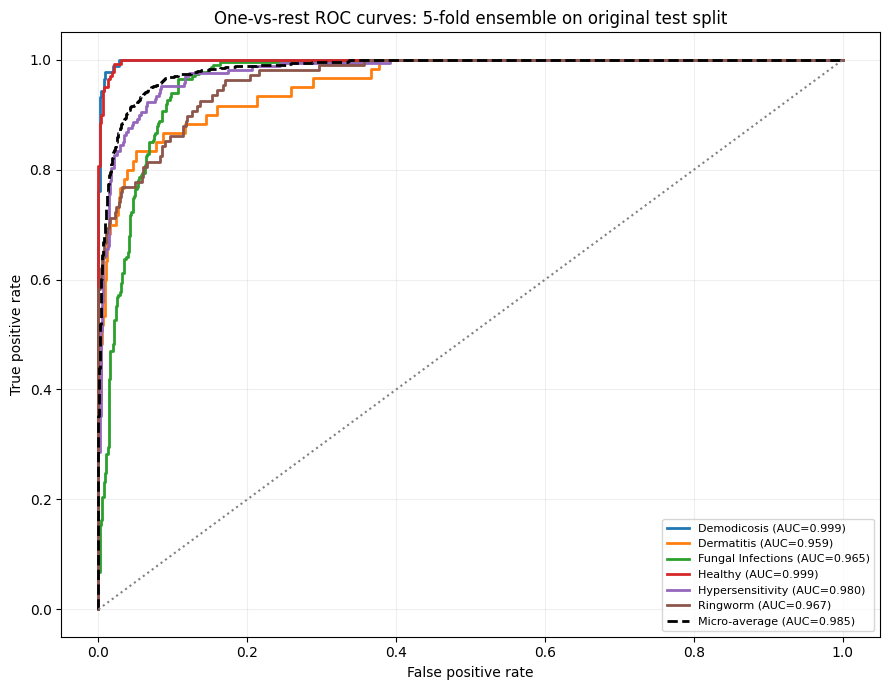

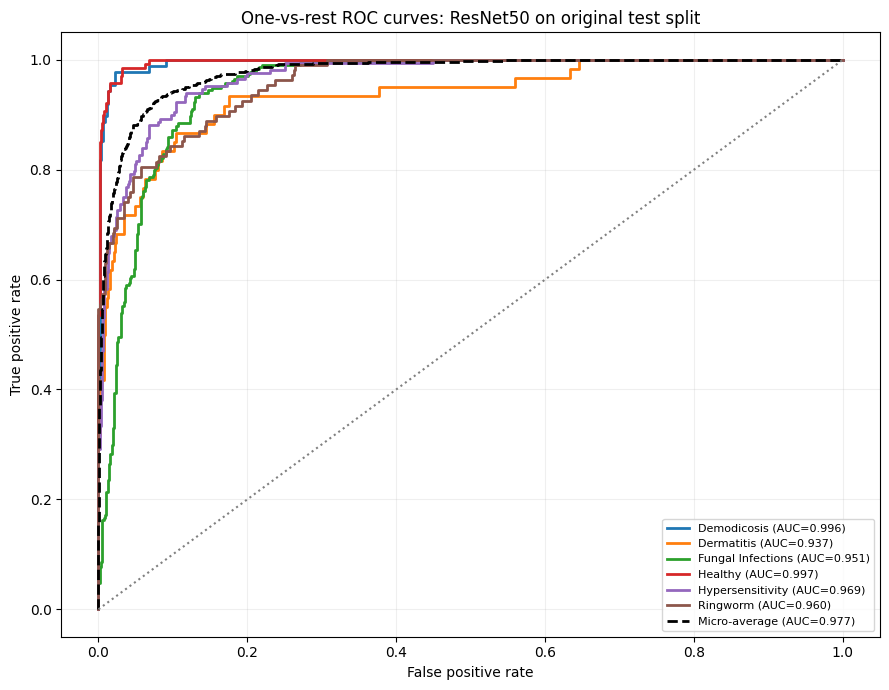

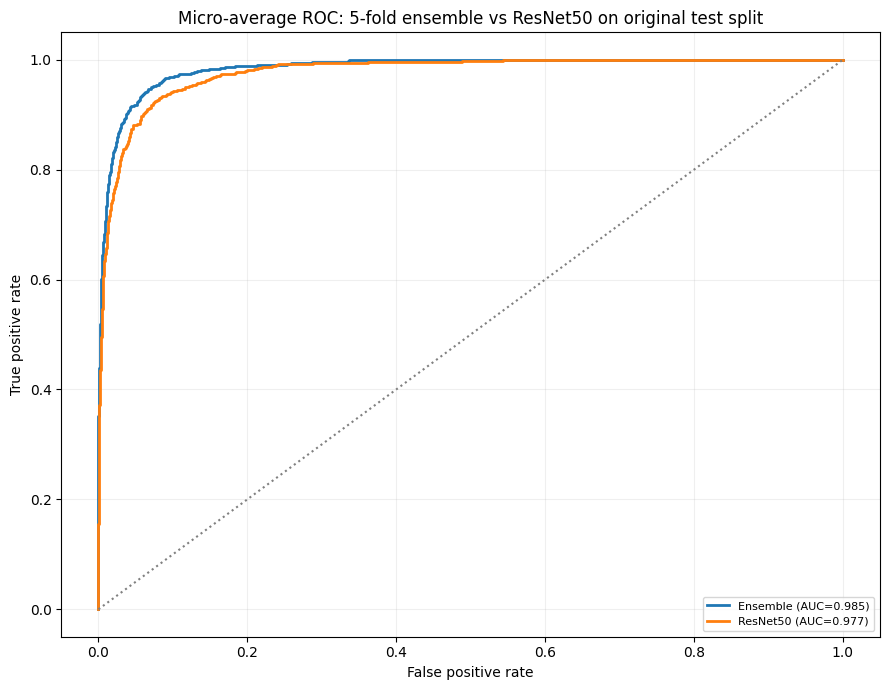

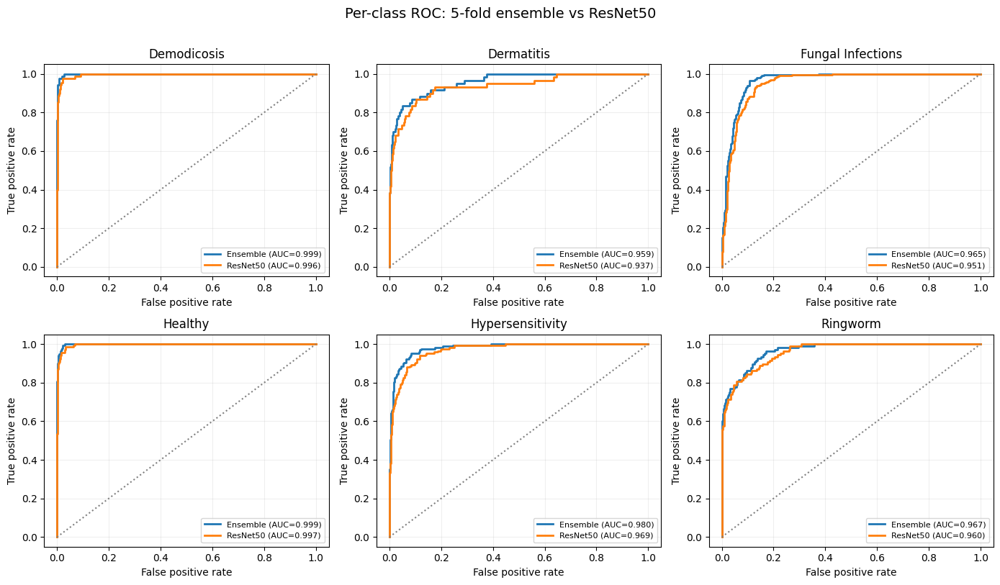


Confusion matrix Ensemble:
 [[ 86   0   1   0   1   0]
 [  1  40   7   1   9   2]
 [  2   1 210   6  12   3]
 [  0   0   5 135   0   0]
 [  3   6   7   1 148   3]
 [  5   1  23   0   4  75]]


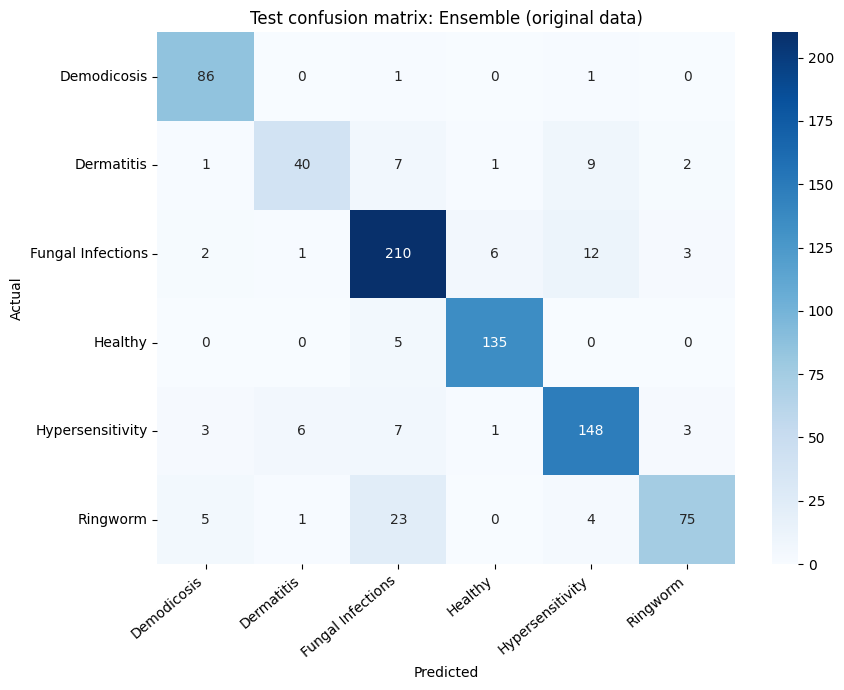

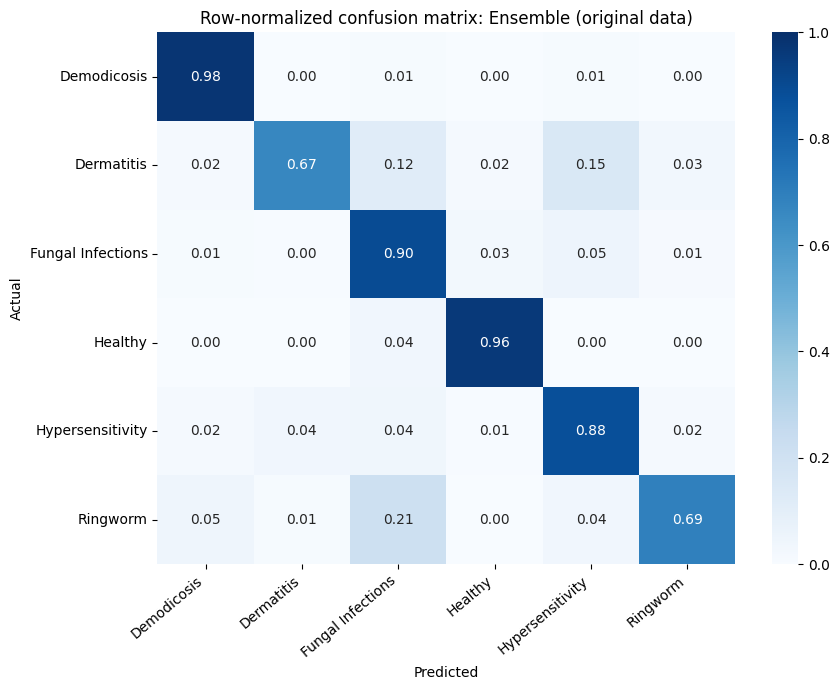


Confusion matrix ResNet50:
 [[ 84   0   2   0   2   0]
 [  1  35   8   1  13   2]
 [  4   1 204   7  15   3]
 [  0   0   8 132   0   0]
 [  4   6  12   2 142   2]
 [  5   3  28   0   5  67]]


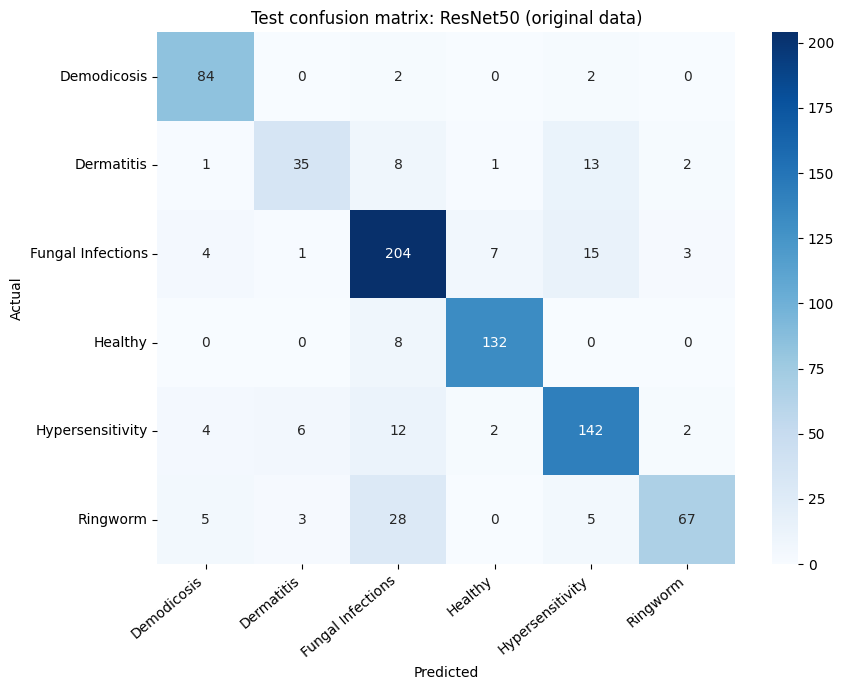

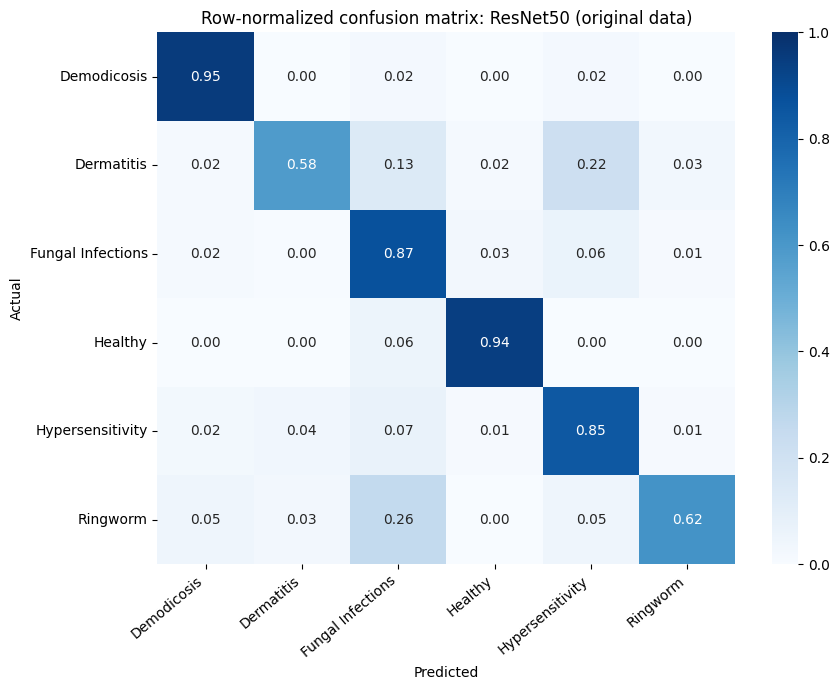


Semua gambar tersimpan di: /content/drive/MyDrive/Machine Learning Group 3/figures/
['confusion_ensemble.pdf', 'confusion_ensemble.png', 'confusion_ensemble_normalized.pdf', 'confusion_ensemble_normalized.png', 'confusion_resnet50.pdf', 'confusion_resnet50.png', 'confusion_resnet50_normalized.pdf', 'confusion_resnet50_normalized.png', 'roc_comparison_micro.pdf', 'roc_comparison_micro.png', 'roc_ensemble.pdf', 'roc_ensemble.png', 'roc_per_class_grid.pdf', 'roc_per_class_grid.png', 'roc_resnet50.pdf', 'roc_resnet50.png']

Ringworm = [5] Ringworm | Fungal = [2] Fungal Infections
Path test diambil dari npz (key: test_paths)
Ensemble: 23 gambar Ringworm salah diprediksi Fungal Infections


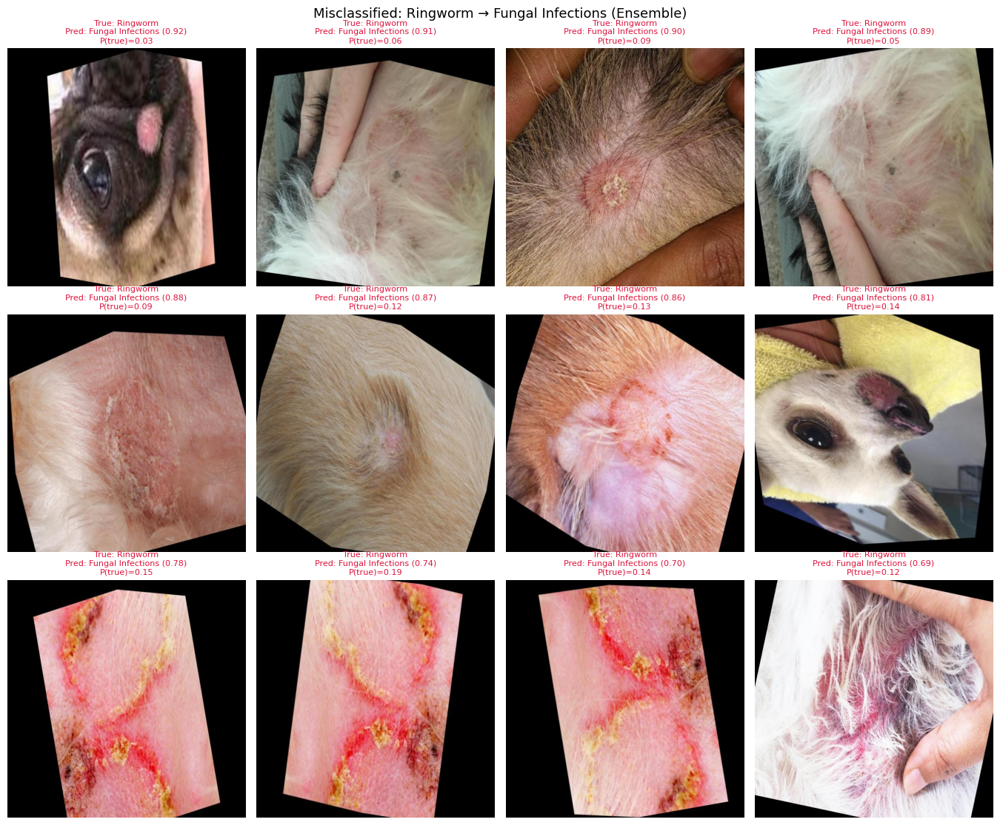

ResNet50: 28 gambar Ringworm salah diprediksi Fungal Infections


In [ ]:
# ============================================================
# FULL: AUC + ROC + Confusion Matrix untuk Ensemble & ResNet50 (run kedua)
# Memuat dari final_predictions.npz, tanpa training ulang.
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import pathlib, os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, roc_auc_score, confusion_matrix, accuracy_score
from sklearn.preprocessing import label_binarize

OUT = '/content/drive/MyDrive/Machine Learning Group 3/'
FIG = OUT + 'figures/'
os.makedirs(FIG, exist_ok=True)
data_dir = pathlib.Path(OUT + 'Dataset Final')

d = np.load(OUT + 'final_predictions.npz', allow_pickle=True)
y_test = d['y_test']
probs = {'Ensemble': d['ens_prob'], 'ResNet50': d['res_prob']}
titles = {
    'Ensemble': 'One-vs-rest ROC curves: 5-fold ensemble on original test split',
    'ResNet50': 'One-vs-rest ROC curves: ResNet50 on original test split',
}

class_names = sorted(p.name for p in data_dir.iterdir() if p.is_dir())
K = len(class_names)
assert K == probs['Ensemble'].shape[1], "Jumlah kelas tidak cocok dengan prediksi"
y_bin = label_binarize(y_test, classes=np.arange(K))

def save(name):
    plt.savefig(FIG + name + '.png', dpi=300, bbox_inches='tight')
    plt.savefig(FIG + name + '.pdf', bbox_inches='tight')

# ---------------- 1. AUC per kelas + micro + macro ----------------
auc_table = {}
for model, p in probs.items():
    per_class = [roc_auc_score(y_bin[:, k], p[:, k]) for k in range(K)]
    fpr_mi, tpr_mi, _ = roc_curve(y_bin.ravel(), p.ravel())
    auc_table[model] = {'per_class': per_class,
                        'micro': auc(fpr_mi, tpr_mi),
                        'macro': float(np.mean(per_class))}
    print(f'\n=== {model} | acc = {accuracy_score(y_test, p.argmax(1)):.4f} ===')
    for k, name in enumerate(class_names):
        print(f'  {name:<20} AUC = {per_class[k]:.3f}')
    print(f'  {"Micro-average":<20} AUC = {auc_table[model]["micro"]:.3f}')
    print(f'  {"Macro-average":<20} AUC = {auc_table[model]["macro"]:.3f}')

print('\n--- LaTeX: tabel AUC ---')
print('Disease Class & ResNet50 & Ensemble \\\\ \\hline')
for k, name in enumerate(class_names):
    print(f'{name} & {auc_table["ResNet50"]["per_class"][k]:.3f} & '
          f'\\textbf{{{auc_table["Ensemble"]["per_class"][k]:.3f}}} \\\\')
print('\\hline')
print(f'Micro-average & {auc_table["ResNet50"]["micro"]:.3f} & \\textbf{{{auc_table["Ensemble"]["micro"]:.3f}}} \\\\')
print(f'Macro-average & {auc_table["ResNet50"]["macro"]:.3f} & \\textbf{{{auc_table["Ensemble"]["macro"]:.3f}}} \\\\ \\hline')

# ---------------- 2. ROC per model (gaya & judul sama dengan gambar asli) ----------------
for model, p in probs.items():
    plt.figure(figsize=(9, 7))
    for k, cname in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_bin[:, k], p[:, k])
        plt.plot(fpr, tpr, lw=2, label=f'{cname} (AUC={auc(fpr, tpr):.3f})')
    fpr_mi, tpr_mi, _ = roc_curve(y_bin.ravel(), p.ravel())
    plt.plot(fpr_mi, tpr_mi, color='black', linestyle='--', lw=2,
             label=f'Micro-average (AUC={auc_table[model]["micro"]:.3f})')
    plt.plot([0, 1], [0, 1], color='gray', linestyle=':')
    plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
    plt.title(titles[model])
    plt.legend(loc='lower right', fontsize=8); plt.grid(alpha=.2)
    plt.tight_layout(); save(f'roc_{model.lower()}'); plt.show()

# ---------------- 3. Perbandingan micro-average ----------------
plt.figure(figsize=(9, 7))
for model, p in probs.items():
    fpr_mi, tpr_mi, _ = roc_curve(y_bin.ravel(), p.ravel())
    plt.plot(fpr_mi, tpr_mi, lw=2, label=f'{model} (AUC={auc_table[model]["micro"]:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle=':')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('Micro-average ROC: 5-fold ensemble vs ResNet50 on original test split')
plt.legend(loc='lower right', fontsize=8); plt.grid(alpha=.2)
plt.tight_layout(); save('roc_comparison_micro'); plt.show()

# ---------------- 4. Per kelas: Ensemble vs ResNet50 (grid 2x3) ----------------
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for k, (ax, cname) in enumerate(zip(axes.ravel(), class_names)):
    for model, p in probs.items():
        fpr, tpr, _ = roc_curve(y_bin[:, k], p[:, k])
        ax.plot(fpr, tpr, lw=2, label=f'{model} (AUC={auc(fpr, tpr):.3f})')
    ax.plot([0, 1], [0, 1], color='gray', linestyle=':')
    ax.set_title(cname); ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
    ax.legend(loc='lower right', fontsize=8); ax.grid(alpha=.2)
plt.suptitle('Per-class ROC: 5-fold ensemble vs ResNet50', y=1.01, fontsize=14)
plt.tight_layout(); save('roc_per_class_grid'); plt.show()

# ---------------- 5. Confusion matrix (jumlah & ternormalisasi) ----------------
for model, p in probs.items():
    cm = confusion_matrix(y_test, p.argmax(1), labels=np.arange(K))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    print(f'\nConfusion matrix {model}:\n', cm)

    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.title(f'Test confusion matrix: {model} (original data)')
    plt.xticks(rotation=40, ha='right'); plt.yticks(rotation=0)
    plt.tight_layout(); save(f'confusion_{model.lower()}'); plt.show()

    plt.figure(figsize=(9, 7))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.title(f'Row-normalized confusion matrix: {model} (original data)')
    plt.xticks(rotation=40, ha='right'); plt.yticks(rotation=0)
    plt.tight_layout(); save(f'confusion_{model.lower()}_normalized'); plt.show()

print('\nSemua gambar tersimpan di:', FIG)
print(sorted(os.listdir(FIG)))

# ---------------- 6. Gambar yang salah: Ringworm diprediksi Fungal Infections ----------------
from PIL import Image
import math

def find_class(keyword):
    idx = [i for i, n in enumerate(class_names) if keyword in n.lower()]
    assert len(idx) == 1, f"Kelas '{keyword}' tidak ditemukan / ambigu di {class_names}"
    return idx[0]

RING = find_class('ringworm')
FUNG = find_class('fungal')
print(f'\nRingworm = [{RING}] {class_names[RING]} | Fungal = [{FUNG}] {class_names[FUNG]}')

# --- Ambil path gambar test ---
path_key = next((k for k in d.files if 'path' in k.lower() or 'file' in k.lower()), None)
if path_key is not None:
    test_paths = [str(p) for p in d[path_key]]
    print(f'Path test diambil dari npz (key: {path_key})')
else:
    # Fallback: urutan file sama seperti image_dataset_from_directory(shuffle=False).
    # Hanya valid kalau test set = seluruh isi folder (atau folder test terpisah).
    # Kalau test split kamu berbeda, simpan path-nya ke npz saat prediksi.
    exts = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
    test_paths = []
    for c in class_names:
        test_paths += sorted(str(p) for p in (data_dir / c).iterdir() if p.suffix.lower() in exts)
    test_paths = np.array(test_paths)
    assert len(test_paths) == len(y_test), (
        f'Jumlah file ({len(test_paths)}) != jumlah y_test ({len(y_test)}). '
        'Simpan path test set ke npz agar akurat.')
    print('Path test direkonstruksi dari folder (fallback)')
test_paths = np.array(test_paths)

def plot_misclassified(model, p, n_cols=4, max_show=12):
    pred = p.argmax(1)
    idx = np.where((y_test == RING) & (pred == FUNG))[0]
    print(f'{model}: {len(idx)} gambar Ringworm salah diprediksi Fungal Infections')
    if len(idx) == 0:
        return
    # urutkan dari yang paling yakin salah
    idx = idx[np.argsort(-p[idx, FUNG])][:max_show]
    n_rows = math.ceil(len(idx) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.4 * n_cols, 3.8 * n_rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis('off')
    for ax, i in zip(axes, idx):
        ax.imshow(Image.open(test_paths[i]).convert('RGB'))
        ax.set_title(f'True: {class_names[RING]}\nPred: {class_names[FUNG]} '
                     f'({p[i, FUNG]:.2f})\nP(true)={p[i, RING]:.2f}',
                     fontsize=8, color='crimson')
    plt.suptitle(f'Misclassified: {class_names[RING]} → {class_names[FUNG]} ({model})',
                 fontsize=13)
    plt.tight_layout()
    save(f'misclassified_ringworm_as_fungal_{model.lower()}')
    plt.show()

for model, p in probs.items():
    plot_misclassified(model, p)

Mounted at /content/drive


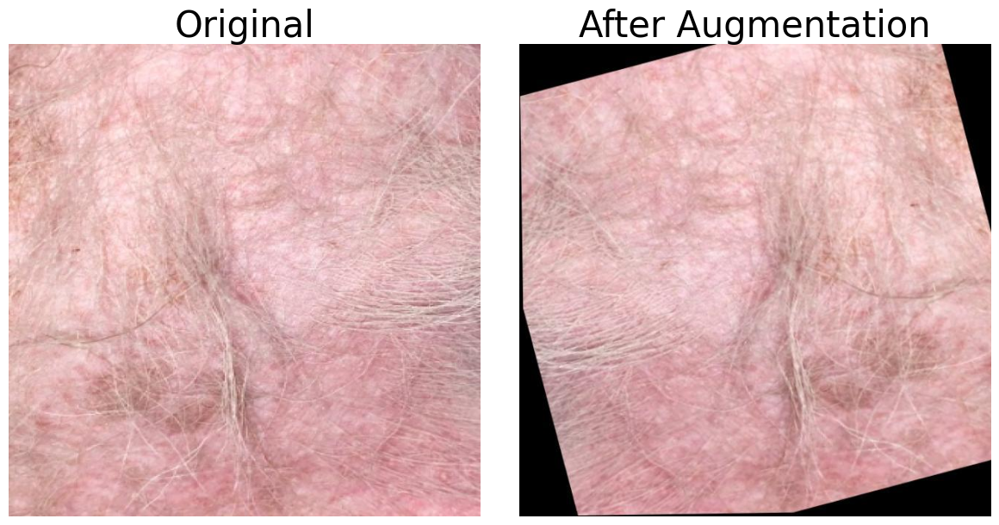

In [2]:
# Connect to Google Drive
from google.colab import drive
drive.mount('/content/drive')

import matplotlib.pyplot as plt
import cv2

# Image paths (Take from any sample of Demodicosis disease in Drive)
img_left_path = "/content/drive/MyDrive/Dataset Gabungan/Demodicosis/1-10-_png_jpg.rf.2dc165ea07aef1847abdab2524e97b27.jpg"
img_right_path = "/content/drive/MyDrive/Dataset Gabungan/Demodicosis/1-10-_png_jpg.rf.52d5ab90bb3854c1af5206e5aed04c9f.jpg"

# Load images (OpenCV loads in BGR → convert to RGB)
img_left = cv2.cvtColor(cv2.imread(img_left_path), cv2.COLOR_BGR2RGB)
img_right = cv2.cvtColor(cv2.imread(img_right_path), cv2.COLOR_BGR2RGB)

# Plot images side by side
plt.figure(figsize=(12, 6))

# Left image
plt.subplot(1, 2, 1)
plt.imshow(img_left)
plt.title("Original", fontsize=30)
plt.axis("off")

# Right image
plt.subplot(1, 2, 2)
plt.imshow(img_right)
plt.title("After Augmentation", fontsize=30)
plt.axis("off")

plt.tight_layout()
plt.show()
